# ¿Cuánto aviso nos da un río? · EDA 1 — Diagnóstico de la cuenca andina del Chancay-Lambayeque (Racarumi y Cirato)

**Curso:** Ciencia de Datos Ambientales (CDA) · Universidad de Ingeniería y Tecnología (UTEC) · Proyecto Integrador, puntos 3.2 a 3.4
**Autor del cuaderno:** Luis Angel Cupe Espinoza · **Equipo:** Luis Angel Cupe Espinoza, Yely Lanasca Justiniano, Lia Kim Alcantara Tineo, Mayra Madelyn Marzano Mejia y María Fernanda Torres Carbajal
**Fecha de ejecución:** se imprime en la celda de configuración.

---

## 0. Portada y objetivo

### 0.1 Contexto dentro del proyecto
El proyecto «¿Cuánto aviso nos da un río?» cuantifica con cuántos días de anticipación se puede pronosticar el caudal diario y avisar de caudales elevados. Su primera parte es un diagnóstico de los datos: se revisaron cuatro cuencas candidatas (dos andinas y dos amazónicas) y se seleccionó una de cada vertiente. Este cuaderno documenta el diagnóstico de la cuenca andina seleccionada, la **cuenca del río Chancay-Lambayeque** (vertiente del Pacífico; Cajamarca y Lambayeque) con las dos estaciones definidas por el equipo:

| Estación | `gauge_id` CAMELS-PE | Rol topológico (de `stations.csv`) |
|---|---|---|
| Racarumi | PE_200907 | Salida del grupo anidado (`downstream_gauge_id = NONE`); recibe a Puente San Carlos (PE_47E1D6C2), que a su vez recibe a Cirato |
| Cirato | PE_4724D566 | Aguas arriba de Racarumi (vía Puente San Carlos); recibe a Puente Amban (PE_47E1E358) y Canad (PE_47E1C5B4) |

### 0.2 Datos
- **Dataset:** CAMELS-PE **v1.0.1** (Llauca et al., 2026; SENAMHI). Serie diaria 1981–2025, unidades de caudal en **mm/día**.
- **Caudal observado (`flow_obs`):** SENAMHI, con control de calidad del propio CAMELS-PE (pruebas de valores negativos, picos > 4σ y líneas planas ≥ 7 días; los vacíos **no** se rellenan).
- **Caudal simulado (`flow_sim`):** producto **PISCO-ARNOVIC v1.1** (ARNO/VIC + RAPID, forzado con PISCO; Llauca et al., 2023), calibrado y validado con 43 estaciones en 1981–2020; no consta si estas dos estaciones estuvieron entre ellas.
- **Advertencia metodológica:** si el `flow_sim` distribuido hubiera sido corregido contra el observado (por ejemplo, por mapeo de cuantiles), las métricas de sesgo (PBIAS, α, β, FHV) estarían cerca de su óptimo por construcción. Por eso se verifica en 2.6 antes de usarlas.
- **Única fuente de datos:** CAMELS-PE v1.0.1 (carpeta o ZIP en la raíz del repositorio). El cuaderno no lee ningún otro archivo.

### 0.3 Pregunta de análisis del diagnóstico
> **¿Qué calidad tienen los registros observados del Chancay-Lambayeque (Racarumi y Cirato) y puede el caudal simulado PISCO-ARNOVIC sustituir al observado en las etapas de modelamiento del proyecto?**

### 0.4 Decisión metodológica: dos niveles de hipótesis
La sección 3.2 del enunciado solo pide "al menos 2 hipótesis verificables con datos". Las preguntas centrales del proyecto (horizonte útil, LSTM vs. modelos clásicos) **requieren modelos de pronóstico**, que un EDA no puede contrastar. Por eso se separan dos niveles:

**Nivel proyecto (HP) — se enuncian aquí y se contrastan en 3.5–3.6 con las dos cuencas seleccionadas:**
- **HP1.** El horizonte útil de pronóstico (último *h* con habilidad frente a la persistencia > 0 y NSE ≥ 0.5) es mayor en la cuenca amazónica seleccionada que en la andina.
- **HP2.** Para *h* = 1–3 días, el LSTM no supera significativamente a los modelos clásicos (regresión lineal, Random Forest).
- **HP3.** El desempeño del pronóstico es menor en caudales extremos (> P95 observado) que en caudales medios.

**Nivel diagnóstico (H) — se contrastan en este cuaderno (sección 7), con criterios fijados antes de ver resultados:**
- **H1 (sustitución).** En cada estación, el simulado (i) supera al benchmark climatológico mensual a escala diaria (BE > 0; Schaefli y Gupta, 2007) y (ii) alcanza desempeño mensual "satisfactorio" (NSE > 0.50 y |PBIAS| ≤ 25 %; Moriasi et al., 2007).
- **H2 (crecidas).** El simulado **subestima** los picos de crecida observados (mediana del error relativo en picos independientes < 0).
- **H3 (estacionalidad del error).** El KGE del simulado **difiere** entre la época húmeda y la seca.
- **H4 (dinámica de corto plazo).** El simulado **reproduce** la variabilidad día a día del observado (índice de Richards-Baker; Baker et al., 2004). H0: RB_sim = RB_obs.

**Por qué estas cuatro:** H1 responde directamente si el simulado puede reemplazar al observado. H2 y H4 evalúan las dos propiedades que más afectan a un sistema de alerta: la magnitud de las crecidas y la "memoria" de la serie (un simulado con memoria distinta a la del río distorsionaría el horizonte útil de HP1). H3 indica en qué época el simulado es confiable.

**Regla de decisión fijada a priori:** el simulado puede sustituir al observado solo si H1 se cumple en las dos estaciones **y** |mediana del error en picos| ≤ 25 % **y** el IC 95 % de H4 incluye la igualdad.

**Decisiones propias de esta cuenca (justificadas en cada sección):** (a) el caudal de estiaje llega a valores cercanos a cero, por lo que todo logaritmo se toma sobre **Q + ε**, con ε = media/100 (el mismo ε del NSE-log; Pushpalatha et al., 2012); (b) se agrega una verificación de **integridad temporal** de cada estación (2.7): un error de fechas no se ve en el formato del archivo ni en las estadísticas descriptivas, pero invalida todas las métricas diarias.

---
## 1. Configuración

Se importan las librerías del material de clase (NumPy, pandas, Matplotlib, Seaborn, SciPy `stats`, statsmodels; Lab3_1, Lab3_2, Lab4_1, Lab4_2, Lab5_1); se fija la semilla y se definen **rutas relativas** y el estilo gráfico.
**Por qué:** reproducibilidad (Restart & Run All) y mismas convenciones que el curso (`fig, ax = plt.subplots(...)`, títulos con fuente, ejes con unidades, `ax.grid(True, alpha=0.3)`). GeoPandas y Folium se usan para el mapa (GeoPandas mencionado en Lab3_1 y Lab2_4; Folium enseñado en Ses2).

In [1]:
# Importaciones estándar (convención del curso: Lab3_1, Lab3_2, Lab4_2, Lab5_1)
import warnings
from pathlib import Path
from datetime import datetime
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
import geopandas as gpd
import folium

%matplotlib inline
warnings.filterwarnings('ignore', category=FutureWarning)

SEMILLA = 42
np.random.seed(SEMILLA)
rng = np.random.default_rng(SEMILLA)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

# Rutas relativas: el cuaderno vive en <raíz del repositorio>/chancay_eda/.
# Única fuente de datos: CAMELS-PE v1.0.1 (carpeta o ZIP en la raíz del repositorio).
RUTA_CAMELS = Path('..') / 'CAMELS-PE_v1.0.1' / 'CAMELS-PE'
RUTA_ZIP = Path('..') / 'CAMELS-PE_v1.0.1.zip'
if not RUTA_CAMELS.exists() and RUTA_ZIP.exists():      # si solo está el ZIP, se extrae solo
    import zipfile
    with zipfile.ZipFile(RUTA_ZIP) as z:
        z.extractall(RUTA_CAMELS.parent)
RUTA_SALIDAS = Path('salidas')
RUTA_FIG = RUTA_SALIDAS / 'figuras'
RUTA_TAB = RUTA_SALIDAS / 'tablas'
for ruta in (RUTA_FIG, RUTA_TAB):
    ruta.mkdir(parents=True, exist_ok=True)

# Estaciones del Chancay-Lambayeque definidas por el equipo (orden: aguas arriba → aguas abajo)
ESTACIONES = {
    'PE_4724D566': 'Cirato',
    'PE_200907': 'Racarumi',
}
COLORES = {'Cirato': '#d62728', 'Racarumi': '#1f77b4'}
FUENTE = 'Fuente: CAMELS-PE v1.0.1 (SENAMHI); simulado PISCO-ARNOVIC v1.1'

# Criterios fijados ANTES de ver resultados (sección 0.4)
ALFA = 0.05
N_BOOT = 1000
NSE_MENSUAL_MIN = 0.50
PBIAS_MAX = 25.0
SESGO_PICOS_MAX = 25.0

print(f"Ejecutado: {datetime.now():%Y-%m-%d %H:%M}")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"seaborn {sns.__version__} | geopandas {gpd.__version__} | folium {folium.__version__}")
print(f"¿Existe la carpeta CAMELS-PE? {RUTA_CAMELS.exists()}")

Ejecutado: 2026-10-27 20:52
Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2 | geopandas 1.2.0 | folium 0.20.0
¿Existe la carpeta CAMELS-PE? True


**Interpretación:** el entorno carga sin errores y encuentra CAMELS-PE con la ruta relativa `../CAMELS-PE_v1.0.1/CAMELS-PE`, así que el cuaderno funciona si se ejecuta desde `chancay_eda/`. La línea de versiones queda impresa para reproducibilidad (ver `requirements.txt`).

### 1.1 Funciones de apoyo
Métricas y utilidades que se reutilizan, documentadas con *docstrings* (convención de Lab2_5) (NSE, KGE con r/α/β, PBIAS, RMSE, NSE-log, BE, curva de duración, FHV/FMS, índice de Richards-Baker, bootstrap por bloques mensuales), y una función propia, `log_q`, que calcula log(Q + ε).
**Por qué `log_q`:** en esta cuenca hay días con caudal 0 o casi 0 (ver 2.5); log(0) no existe y valores como 0.01 m³/s dominarían cualquier estadístico en escala log. Sumar ε = media/100 es la convención de Pushpalatha et al. (2012), ya usada en el NSE-log.

Convención de signo: **PBIAS = 100·Σ(sim − obs)/Σobs** (positivo = el simulado sobreestima).

In [2]:
def mmd_a_m3s(q_mmd, area_km2):
    """Convierte caudal específico (mm/día) a caudal (m³/s): Q = q · A · 1000 / 86400."""
    return q_mmd * area_km2 * 1000.0 / 86400.0


def log_q(q, eps=None):
    """log(Q + ε), con ε = media(Q)/100 si no se indica (Pushpalatha et al., 2012)."""
    q = pd.Series(q, dtype=float) if not isinstance(q, pd.Series) else q.astype(float)
    eps = q.mean() / 100 if eps is None else eps
    return np.log(q + eps)


def nse(obs, sim):
    """Eficiencia de Nash–Sutcliffe (1970)."""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    return 1 - np.sum((obs - sim) ** 2) / np.sum((obs - obs.mean()) ** 2)


def kge(obs, sim):
    """KGE de Gupta et al. (2009). Retorna (KGE, r, alfa, beta)."""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    r = np.corrcoef(obs, sim)[0, 1]
    alfa = sim.std() / obs.std()
    beta = sim.mean() / obs.mean()
    return 1 - np.sqrt((r - 1) ** 2 + (alfa - 1) ** 2 + (beta - 1) ** 2), r, alfa, beta


def pbias(obs, sim):
    """Sesgo porcentual: 100·Σ(sim−obs)/Σobs (positivo = sobreestimación)."""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    return 100 * np.sum(sim - obs) / np.sum(obs)


def rmse(obs, sim):
    """Raíz del error cuadrático medio (m³/s)."""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    return np.sqrt(np.mean((obs - sim) ** 2))


def nse_log(obs, sim):
    """NSE sobre log(Q + ε), ε = media(obs)/100 (Pushpalatha et al., 2012)."""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    eps = obs.mean() / 100
    return nse(np.log(obs + eps), np.log(sim + eps))


def eficiencia_benchmark(obs, sim, bench):
    """BE = 1 − Σ(obs−sim)² / Σ(obs−bench)² (Schaefli y Gupta, 2007)."""
    obs, sim, bench = (np.asarray(x, float) for x in (obs, sim, bench))
    return 1 - np.sum((obs - sim) ** 2) / np.sum((obs - bench) ** 2)


def curva_duracion(q):
    """Caudales ordenados de mayor a menor y probabilidad de excedencia (Weibull, i/(n+1))."""
    q = np.sort(np.asarray(q, float))[::-1]
    return np.arange(1, len(q) + 1) / (len(q) + 1), q


def fhv(obs, sim, p_alta=0.02):
    """FHV (Yilmaz et al., 2008): % de sesgo en el volumen del 2 % de caudales más altos."""
    _, qo = curva_duracion(obs)
    _, qs = curva_duracion(sim)
    k = max(1, int(np.floor(p_alta * len(qo))))
    return 100 * (qs[:k].sum() - qo[:k].sum()) / qo[:k].sum()


def fms(obs, sim, p1=0.2, p2=0.7):
    """FMS (Yilmaz et al., 2008): % de sesgo en la pendiente (log) del tramo 20–70 % de la curva de duración."""
    po, qo = curva_duracion(obs)
    ps, qs = curva_duracion(sim)
    qo1, qo2 = np.interp([p1, p2], po, qo)
    qs1, qs2 = np.interp([p1, p2], ps, qs)
    return 100 * ((np.log(qs1) - np.log(qs2)) - (np.log(qo1) - np.log(qo2))) / (np.log(qo1) - np.log(qo2))


def richards_baker(q):
    """Índice de Richards-Baker (Baker et al., 2004): Σ|Q_t − Q_{t−1}| / ΣQ_t, sobre días consecutivos."""
    q = pd.Series(q).astype(float)
    dq = q.diff().abs()
    validos = dq.notna()
    return dq[validos].sum() / q[validos].sum()


def bootstrap_bloques_mensuales(df, estadistico, n_boot=N_BOOT, semilla=SEMILLA):
    """Bootstrap por bloques: remuestrea meses calendario completos con reemplazo (Clark et al., 2021)."""
    gen = np.random.default_rng(semilla)
    clave = df.index.year * 100 + df.index.month
    posiciones = [np.flatnonzero(clave == k) for k in np.unique(clave)]
    replicas = np.empty(n_boot)
    for b in range(n_boot):
        idx = gen.integers(0, len(posiciones), len(posiciones))
        replicas[b] = estadistico(df.iloc[np.concatenate([posiciones[i] for i in idx])])
    return replicas


def lag_max_correlacion(a, b, rezagos):
    """Rezago l que maximiza corr(a_t, b_{t−l}). Retorna (l, r). l > 0: b va adelantada respecto de a."""
    c = {l: a.corr(b.shift(l)) for l in rezagos}
    c = {k: v for k, v in c.items() if pd.notna(v)}
    if not c:
        return np.nan, np.nan
    mejor = max(c, key=c.get)
    return mejor, c[mejor]


def nota_fuente(fig, texto=FUENTE):
    """Agrega la fuente de datos al pie de la figura."""
    fig.text(0.01, -0.01, texto, fontsize=8, color='gray', ha='left', va='top')


print('Funciones definidas: mmd_a_m3s, log_q, nse, kge, pbias, rmse, nse_log, eficiencia_benchmark, curva_duracion, '
      'fhv, fms, richards_baker, bootstrap_bloques_mensuales, lag_max_correlacion, nota_fuente')

Funciones definidas: mmd_a_m3s, log_q, nse, kge, pbias, rmse, nse_log, eficiencia_benchmark, curva_duracion, fhv, fms, richards_baker, bootstrap_bloques_mensuales, lag_max_correlacion, nota_fuente


**Interpretación:** las funciones quedan disponibles para todo el cuaderno. Tres decisiones condicionan los resultados:
- **Bootstrap por meses completos:** los IC reflejan la dependencia temporal del caudal.
- **`log_q`:** suma ε antes del logaritmo, porque Racarumi registra días con caudal 0 (ver 2.5).
- **Signo del PBIAS:** positivo significa que el simulado sobreestima.

`lag_max_correlacion` es la base de la verificación de integridad temporal (2.7).

---
## 2. Carga e inspección inicial

### 2.1 Metadatos y atributos de cuenca
`stations.csv` y los siete archivos de `02_attributes/` se unen por `gauge_id` con `merge` (Programación Sesión 5 – Pandas); se filtran las dos estaciones y se muestran además algunos atributos de **todo el grupo anidado** (6 estaciones) para revisar su coherencia.
**Por qué:** el área es indispensable para convertir mm/día a m³/s; los atributos se usan en 6.4 y su coherencia condiciona esa comparación.

In [3]:
estaciones = pd.read_csv(RUTA_CAMELS / '01_metadata' / 'stations.csv')
diccionario = pd.read_csv(RUTA_CAMELS / '01_metadata' / 'data_dictionary.csv')

archivos_atrib = sorted((RUTA_CAMELS / '02_attributes').glob('*.csv'))
atributos = estaciones.copy()
for archivo in archivos_atrib:
    atributos = atributos.merge(pd.read_csv(archivo), on='gauge_id', how='left')

atrib = atributos[atributos['gauge_id'].isin(ESTACIONES)].set_index('gauge_id').loc[list(ESTACIONES)]
atrib['estacion'] = atrib.index.map(ESTACIONES)

print(f"stations.csv: {estaciones.shape[0]} estaciones | atributos unidos: {atributos.shape[1]} columnas "
      f"de {len(archivos_atrib)} archivos")
cols_ver = ['estacion', 'gauge_lat', 'gauge_lon', 'gauge_elev', 'gauge_record_start', 'gauge_record_end',
            'gauge_perc_obs', 'area', 'elev_mean', 'p_mean', 'pet_mean', 'aridity', 'high_prec_timing',
            'agricul_perc', 'forest_perc', 'baseflow_index', 'zero_q_freq', 'reservoir_n', 'reservoir_use',
            'downstream_gauge_id', 'upstream_gauge_id']
display(atrib[cols_ver].T)

grupo = atributos[atributos['nested_group_id'] == 'PE_200907'].set_index('gauge_id')
print('\nGrupo anidado (nested_group_id = PE_200907): coherencia de atributos geométricos')
print(grupo[['gauge_name', 'area', 'perimeter', 'slope_mean', 'elev_min', 'elev_max', 'downstream_gauge_id']].to_string())

stations.csv: 136 estaciones | atributos unidos: 79 columnas de 7 archivos


gauge_id,PE_4724D566,PE_200907
estacion,Cirato,Racarumi
gauge_lat,-6.656,-6.633
gauge_lon,-79.074,-79.317
gauge_elev,960,265
gauge_record_start,2008-11-28,1981-01-01
gauge_record_end,2025-12-31,2023-08-31
gauge_perc_obs,37.76,94.51
area,1611.901,2363.302
elev_mean,2630.597,2348.974
p_mean,3.502,3.007



Grupo anidado (nested_group_id = PE_200907): coherencia de atributos geométricos
                    gauge_name      area  perimeter  slope_mean  elev_min  elev_max downstream_gauge_id
gauge_id                                                                                               
PE_4724D566             Cirato  1611.901     99.213      10.001    946.85   4097.00         PE_47E1D6C2
PE_47E1E358       Puente Amban   736.882   2016.007       9.071   1509.95   4097.00         PE_4724D566
PE_47E1D6C2  Puente San Carlos  2303.559    235.845      11.459    324.23   4097.00           PE_200907
PE_47E207A4             Tongod   277.972     72.174       9.071   2484.23   4097.00         PE_47E1E358
PE_47E1C5B4              Canad   243.723     84.994       9.075   1185.07   3812.87         PE_4724D566
PE_200907             Racarumi  2363.302   7422.198      11.545    266.36   4097.00                NONE


**Interpretación:** Cirato (1 612 km²) drena hacia Puente San Carlos y esta hacia Racarumi (2 363 km²), la salida del grupo anidado de 6 estaciones.

**Rasgos que condicionan el análisis:**
- **Clima:** cuenca semiárida a subhúmeda (aridez 0.91 en Cirato y 1.06 en Racarumi), con lluvia concentrada en MAM.
- **Flujo base:** índice de 0.52–0.55; aproximadamente la mitad del caudal viene del flujo lento.
- **Uso del suelo:** fuertemente agrícola (68 % y 53 %).
- **Intervención:** CAMELS-PE registra **presas de uso minero** (3 en la cuenca de Cirato y 6 en la de Racarumi) y 3 captaciones superficiales.
- **Registro:**
  - Racarumi: 1981-01-01 a **2023-08-31** (94.5 % de días con dato en 1981–2025).
  - Cirato: desde 2008-11-28 (37.8 %).

**Atributos incoherentes:**
- El `perimeter` de Racarumi (7 422 km) es absurdo para 2 363 km².
- La `slope_mean` se repite en pares (9.071 en Puente Amban y Tongod; 9.075 en Canad).

No se usan. El área sí se valida en 2.3.

### 2.2 Series diarias (observado y simulado)
Lectura de `03_timeseries/by_catchment/PE_XXXX.csv` con `parse_dates` y la fecha como índice (Lab5_1); verificación de tipos, orden, duplicados y continuidad del calendario.
**Por qué:** un índice desordenado o con días faltantes produciría remuestreos y rezagos erróneos.

In [4]:
series = {}
for gid, nombre in ESTACIONES.items():
    df = pd.read_csv(RUTA_CAMELS / '03_timeseries' / 'by_catchment' / f'{gid}.csv', parse_dates=['date'])
    series[nombre] = df.set_index('date').sort_index()

control = []
for nombre, df in series.items():
    calendario = pd.date_range(df.index.min(), df.index.max(), freq='D')
    control.append({'estación': nombre, 'filas': len(df), 'inicio': df.index.min().date(), 'fin': df.index.max().date(),
                    'fechas duplicadas': int(df.index.duplicated().sum()),
                    'índice ordenado': df.index.is_monotonic_increasing,
                    'días ausentes del calendario': len(calendario.difference(df.index)),
                    'tipos numéricos': all(pd.api.types.is_float_dtype(t) for t in df.dtypes)})
print('Columnas:', list(series['Racarumi'].columns))
pd.DataFrame(control).set_index('estación')

Columnas: ['prec', 'prec_var', 'flow_obs', 'flow_sim', 'pet', 'tmin', 'tmean', 'tmax', 'srad', 'vprp']


,filas,inicio,fin,fechas duplicadas,índice ordenado,días ausentes del calendario,tipos numéricos
estación,,,,,,,
Cirato,16436,1981-01-01,2025-12-31,0,True,0,True
Racarumi,16436,1981-01-01,2025-12-31,0,True,0,True


**Interpretación:** ambas series tienen 16 436 filas (1981-01-01 a 2025-12-31), sin fechas duplicadas ni días ausentes del calendario, y todas sus columnas son numéricas. El formato es correcto. Como se verá en 2.7, eso **no garantiza** que los valores estén asignados a la fecha correcta.

### 2.3 Coherencia de identificadores, unidades y áreas
Tres comprobaciones: (a) que los `gauge_id` existan en metadatos, atributos y GeoPackage; (b) la unidad de `flow_obs` y `flow_sim` en `data_dictionary.csv`; (c) el área del atributo frente al área del polígono reproyectado a UTM 17S (EPSG:32717; la cuenca está al oeste de 78° O; Lab5_2).
**Por qué:** la conversión a m³/s depende del área.

In [5]:
cuencas_gpkg = gpd.read_file(RUTA_CAMELS / '04_geospatial' / 'camels_pe_catchments.gpkg')
puntos_gpkg = gpd.read_file(RUTA_CAMELS / '04_geospatial' / 'camels_pe_gauges.gpkg')

ids = set(ESTACIONES)
print('IDs en stations.csv     :', ids <= set(estaciones['gauge_id']))
print('IDs en atributos        :', ids <= set(atrib.index))
print('IDs en cuencas (gpkg)   :', ids <= set(cuencas_gpkg['gauge_id']))
print('IDs en estaciones (gpkg):', ids <= set(puntos_gpkg['gauge_id']))
print('CRS de los GeoPackage   :', cuencas_gpkg.crs.to_string(), '|', puntos_gpkg.crs.to_string())

print('\nUnidades según data_dictionary.csv:')
print(diccionario.loc[diccionario['variable'].isin(['flow_obs', 'flow_sim', 'prec', 'area']),
                      ['variable', 'unit', 'source']].to_string(index=False))

area_poligono = (cuencas_gpkg[cuencas_gpkg['gauge_id'].isin(ids)].to_crs(epsg=32717).set_index('gauge_id').area / 1e6)
tabla_area = pd.DataFrame({'estación': atrib['estacion'], 'área atributo (km²)': atrib['area'],
                           'área polígono UTM17S (km²)': area_poligono.reindex(atrib.index).round(1)})
tabla_area['diferencia (%)'] = (100 * (tabla_area.iloc[:, 2] - tabla_area.iloc[:, 1]) / tabla_area.iloc[:, 1]).round(3)
print('\n', tabla_area.to_string())

IDs en stations.csv     : True
IDs en atributos        : True
IDs en cuencas (gpkg)   : True
IDs en estaciones (gpkg): True
CRS de los GeoPackage   : EPSG:4326 | EPSG:4326

Unidades según data_dictionary.csv:
variable   unit             source
    area    km2        FABDEM v1.2
    prec mm/day        PISCOp v2.1
flow_obs mm/day  Observed stations
flow_sim mm/day PISCO-ARNOVIC v1.1

              estación  área atributo (km²)  área polígono UTM17S (km²)  diferencia (%)
gauge_id                                                                              
PE_4724D566    Cirato             1611.901                      1612.8           0.056
PE_200907    Racarumi             2363.302                      2364.4           0.046


**Interpretación:** los IDs existen en todos los componentes, los GeoPackage están en EPSG:4326 y el caudal está en **mm/día**. El área del atributo y la del polígono difieren en +0.06 % (Cirato) y +0.05 % (Racarumi): el área es confiable para convertir unidades.

### 2.4 Conversión a m³/s
Observado y simulado se convierten a m³/s con el área de cada cuenca; se imprime la relación de áreas.
**Por qué:** las comparaciones entre estaciones y con umbrales se hacen en m³/s. La verificación por balance (Racarumi vs Cirato) se hace en 2.8, **después** de verificar la integridad temporal (2.7), porque un balance con fechas desfasadas no tiene sentido.

In [6]:
area = atrib.set_index('estacion')['area']
for nombre, df in series.items():
    df['qobs'] = mmd_a_m3s(df['flow_obs'], area[nombre])
    df['qsim'] = mmd_a_m3s(df['flow_sim'], area[nombre])

area_intermedia = area['Racarumi'] - area['Cirato']
p_intermedia = (atrib.set_index('estacion')['p_mean']['Racarumi'] * area['Racarumi']
                - atrib.set_index('estacion')['p_mean']['Cirato'] * area['Cirato']) / area_intermedia
print(f"Área Cirato: {area['Cirato']:.1f} km² | Racarumi: {area['Racarumi']:.1f} km² | "
      f"área intermedia: {area_intermedia:.1f} km² ({100 * area_intermedia / area['Racarumi']:.1f} % de Racarumi)")
print(f"Lluvia media (p_mean, mm/d): Cirato = {atrib.set_index('estacion')['p_mean']['Cirato']:.3f}; "
      f"Racarumi = {atrib.set_index('estacion')['p_mean']['Racarumi']:.3f}; "
      f"área intermedia (por balance de áreas) = {p_intermedia:.3f}")

Área Cirato: 1611.9 km² | Racarumi: 2363.3 km² | área intermedia: 751.4 km² (31.8 % de Racarumi)
Lluvia media (p_mean, mm/d): Cirato = 3.502; Racarumi = 3.007; área intermedia (por balance de áreas) = 1.945


**Interpretación:** el área intermedia entre Cirato y Racarumi es de 751.4 km², el **31.8 %** del área de Racarumi, e incluye a Puente San Carlos. Por balance de áreas recibe **1.95 mm/d** de lluvia media, frente a 3.50 mm/d en Cirato: es la parte baja y más seca. Por eso cabe esperar que Racarumi lleve algo más de agua que Cirato, pero menos que la proporción de áreas (×1.47).

### 2.5 Tabla resumen por estación y por serie
Periodo, n, % de vacíos, mínimo, máximo, media, mediana, CV y asimetría del observado (en su periodo), del simulado en las **mismas fechas** y del simulado completo, en m³/s; además, número de días con Q < 0.5 m³/s.
**Por qué:** comparar observado y simulado solo es justo sobre fechas pareadas; asimetría y CV orientan las transformaciones y las pruebas no paramétricas (Lab3_2).

In [7]:
def resumen_serie(s, nombre_serie):
    """Estadísticos descriptivos de una serie diaria de caudal (m³/s)."""
    tramo = s.loc[s.first_valid_index():s.last_valid_index()]
    return {'serie': nombre_serie, 'inicio': tramo.index.min().date(), 'fin': tramo.index.max().date(),
            'n válidos': int(tramo.notna().sum()), '% vacíos (en su periodo)': round(100 * tramo.isna().mean(), 2),
            'mín': round(tramo.min(), 3), 'máx': round(tramo.max(), 1), 'media': round(tramo.mean(), 2),
            'mediana': round(tramo.median(), 2), 'CV': round(tramo.std() / tramo.mean(), 3),
            'asimetría': round(stats.skew(tramo.dropna()), 3), 'días Q < 0.5 m³/s': int((tramo < 0.5).sum())}

filas = []
for nombre, df in series.items():
    for fila in (resumen_serie(df['qobs'], 'observado'),
                 resumen_serie(df['qsim'].where(df['qobs'].notna()), 'simulado (fechas pareadas)'),
                 resumen_serie(df['qsim'], 'simulado (1981–2025)')):
        filas.append({'estación': nombre, **fila})
tabla_resumen = pd.DataFrame(filas).set_index(['estación', 'serie'])
tabla_resumen.to_csv(RUTA_TAB / 'tabla_resumen_series.csv')
tabla_resumen

inicio         fin  n válidos  \
estación serie                                                           
Cirato   observado                   2008-11-28  2025-12-31       6207   
         simulado (fechas pareadas)  2008-11-28  2025-12-31       6207   
         simulado (1981–2025)        1981-01-01  2025-12-31      16436   
Racarumi observado                   1981-01-01  2023-08-31      15533   
         simulado (fechas pareadas)  1981-01-01  2023-08-31      15533   
         simulado (1981–2025)        1981-01-01  2025-12-31      16436   

                                     % vacíos (en su periodo)    mín    máx  \
estación serie                                                                
Cirato   observado                                       0.58  5.056  240.7   
         simulado (fechas pareadas)                      0.58  5.056  240.7   
         simulado (1981–2025)                            0.00  5.056  240.7   
Racarumi observado                                       0.32  0.000  396.5   
         simulado (fechas pareadas)                      0.32  0.000  396.5   
         simulado (1981–2025)                            0.00  0.000  396.5   

                                     media  mediana     CV  asimetría  \
estación serie                                                          
Cirato   observado                   37.65    24.25  0.945      1.479   
         simulado (fechas pareadas)  37.72    24.46  0.938      1.443   
         simulado (1981–2025)        36.64    23.36  0.966      1.563   
Racarumi observado                   35.61    20.19  1.092      2.317   
         simulado (fechas pareadas)  35.81    20.46  1.096      2.330   
         simulado (1981–2025)        36.03    20.68  1.092      2.285   

                                     días Q < 0.5 m³/s  
estación serie                                          
Cirato   observado                                   0  
         simulado (fechas pareadas)                  0  
         simulado (1981–2025)                        0  
Racarumi observado                                   5  
         simulado (fechas pareadas)                  3  
         simulado (1981–2025)                        3

**Interpretación:**
- **Caudales parecidos en ambas estaciones:** medias de 37.65 (Cirato) y 35.61 m³/s (Racarumi), aunque Racarumi drena 1.47 veces más área. Es la primera señal de que entre ambas se pierde o se deriva agua (ver 2.8).
- **Régimen:** asimétrico (asimetría 1.5–2.3; CV 0.94–1.09). Racarumi tiene **5 días con Q = 0**, imposibles en un río que en esas fechas lleva decenas de m³/s (ver 4.3).
- **Huella del mapeo de cuantiles:** en ambas estaciones el simulado 1981–2025 tiene **exactamente** el mismo mínimo y máximo que el observado (5.056 y 240.7 m³/s en Cirato; 0 y 396.5 m³/s en Racarumi). Se analiza en 2.6.

### 2.6 ¿Es el simulado independiente del observado?
(a) Máximo y mínimo del simulado 1981–2025 frente a los del observado, y fecha de cada máximo; (b) prueba de coincidencia exacta de valores **en la cola alta** (simulado fuera del periodo observado y mayor que el P90 observado en mm/d), frente a controles desplazados +0.001, +0.002 y +0.005 mm/d.
**Por qué restringir a la cola alta:** el caudal específico de esta cuenca es moderado (media ≈ 1.3–2.0 mm/d) y con 3 decimales casi todos los valores bajos existen en el observado, así que la coincidencia en todo el rango sería alta por azar (los controles también lo serían). En la cola alta los valores son escasos y la prueba sí discrimina.

In [8]:
filas = []
for nombre, df in series.items():
    obs = df['flow_obs'].dropna()
    p90 = obs.quantile(0.90)
    obs_val = np.unique(np.round(obs.values, 3))
    sim_cola = np.round(df.loc[df['flow_obs'].isna() & (df['flow_sim'] > p90), 'flow_sim'].values, 3)
    fila = {'estación': nombre,
            'máx obs (m³/s)': round(df['qobs'].max(), 1), 'fecha máx obs': df['qobs'].idxmax().date(),
            'máx sim (m³/s)': round(df['qsim'].max(), 1), 'fecha máx sim': df['qsim'].idxmax().date(),
            'máx obs = máx sim': bool(np.isclose(df['flow_obs'].max(), df['flow_sim'].max())),
            'mín obs (m³/s)': round(df['qobs'].min(), 3), 'mín sim (m³/s)': round(df['qsim'].min(), 3),
            'n sim cola alta': len(sim_cola),
            'coincidencia exacta cola alta (%)': 100 * np.isin(sim_cola, obs_val).mean()}
    for despl in (0.001, 0.002, 0.005):
        fila[f'control +{despl} (%)'] = 100 * np.isin(sim_cola, np.round(obs_val + despl, 3)).mean()
    filas.append(fila)
pd.DataFrame(filas).set_index('estación').round(1).T

estación,Cirato,Racarumi
máx obs (m³/s),240.7,396.5
fecha máx obs,2022-03-16,2022-03-03
máx sim (m³/s),240.7,396.5
fecha máx sim,2023-03-13,2023-03-14
máx obs = máx sim,True,True
mín obs (m³/s),5.1,0.0
mín sim (m³/s),5.1,0.0
n sim cola alta,1008,119
coincidencia exacta cola alta (%),33.6,60.5
control +0.001 (%),23.1,50.4


**Interpretación:**
- **Máximos y mínimos:** el máximo simulado (240.7 y 396.5 m³/s) es **idéntico al máximo observado**, pero cae en otra fecha: **2023-03-13/14** en el simulado frente a 2022-03-16 y 2022-03-03 en el observado. Los mínimos también coinciden (5.056 y 0.000 m³/s).
- **Cola alta:** la coincidencia exacta de valores es mayor que en los controles: 33.6 % frente a 18–23 % en Cirato, y 60.5 % frente a 42–50 % en Racarumi.

**Interpretación conjunta:** es la huella de una corrección por **mapeo de cuantiles** contra el observado. El evento más grande del modelo recibe el valor del mayor caudal observado, aunque ocurra en otro año.

**Consecuencia:** PBIAS, α, β y FHV estarán cerca de su óptimo por construcción y no prueban habilidad. Lo informativo es r, NSE, BE, picos y *flashiness*.

### 2.7 Integridad temporal: ¿Cirato y Racarumi son registros independientes y bien fechados?
**Procedimiento:**
1. **Por año**, busca el desfase (0–40 días) que maximiza la correlación entre las variaciones diarias Δlog(Q + ε) de Cirato y de Racarumi desplazada, y cuenta qué fracción de días de Cirato tiene **exactamente** el mismo caudal en m³/s que Racarumi con ese desfase (tolerancia = media unidad de redondeo del archivo en ambas estaciones). Control: la misma fracción con el desfase + 7 días.
2. **Por año**, busca el desfase observado–simulado de cada estación (−10 a +30 días). El simulado está forzado por lluvia PISCO bien fechada, así que es una referencia temporal independiente de ambas estaciones.
3. Con **ventanas móviles de 120 días** (inicio cada mes) estima el desfase obs–sim y define, de forma automática, el **inicio del periodo con fechas confiables** de cada estación: el primer inicio de ventana cuyo desfase es |l| ≤ 2 días después de la última ventana cuya mediana móvil (5 ventanas) excede 2 días. Solo se usan ventanas con correlación ≥ 0.3 (en recesiones suaves la correlación no discrimina el desfase).

**Por qué Δlog y no log(Q):** en una recesión cualquier par de curvas decrecientes se correlaciona bien con casi cualquier desfase; las variaciones diarias resaltan las crecidas, que sí fijan el tiempo.
**Por qué importa:** un error de fechas o una serie copiada de otra estación no se detecta en el formato del archivo (2.2) ni en las estadísticas descriptivas (2.5), pero invalida todas las métricas diarias. Si una serie está desfasada, todas las métricas diarias (NSE, KGE, picos, tiempo de respuesta) serían erróneas.

In [9]:
tol_m3s = 0.0005 * (area['Cirato'] + area['Racarumi']) * 1000 / 86400   # media unidad de redondeo (3 decimales, mm/d)
dlog = {n: log_q(df['qobs']).diff() for n, df in series.items()}
dlog_sim = {n: log_q(df['qsim'], df['qobs'].mean() / 100).diff() for n, df in series.items()}
q_ci, q_ra = series['Cirato']['qobs'], series['Racarumi']['qobs']

filas = []
for anio in range(1981, 2026):
    x = slice(f'{anio}-01-01', f'{anio}-12-31')
    fila = {'año': anio}
    for n in ESTACIONES.values():
        if series[n]['qobs'].loc[x].notna().sum() >= 150:
            fila[f'desfase obs–sim {n} (d)'] = lag_max_correlacion(dlog[n].loc[x], dlog_sim[n], range(-10, 31))[0]
    if q_ci.loc[x].notna().sum() >= 150 and q_ra.loc[x].notna().sum() >= 150:
        l, r = lag_max_correlacion(dlog['Cirato'].loc[x], dlog['Racarumi'], range(-5, 41))
        fila['desfase Cirato–Racarumi (d)'] = l
        fila['r Δlog (con desfase)'] = r
        for etiqueta, desfase in (('% idénticos a Racarumi desplazado', l), ('control: desfase + 7 d (%)', l + 7)):
            ra_d = q_ra.shift(desfase).loc[x]
            ok = q_ci.loc[x].notna() & ra_d.notna() & (q_ci.loc[x] >= 0.5)
            fila[etiqueta] = 100 * ((q_ci.loc[x] - ra_d).abs() <= tol_m3s)[ok].mean()
    filas.append(fila)
tabla_integridad = pd.DataFrame(filas).set_index('año')
tabla_integridad.to_csv(RUTA_TAB / 'tabla_integridad_temporal.csv')
print(f"Tolerancia para 'idéntico': {tol_m3s:.3f} m³/s")
display(tabla_integridad.round(2))

# Ventanas móviles de 120 días: desfase obs–sim y periodo confiable
ventanas, inicio_confiable = {}, {}
for n, df in series.items():
    filas_v = []
    for ini in pd.date_range('1981-01-01', '2025-09-01', freq='MS'):
        fin = ini + pd.Timedelta(days=119)
        if df['qobs'].loc[ini:fin].notna().sum() < 84:          # ≥ 70 % de días con dato
            continue
        l, r = lag_max_correlacion(dlog[n].loc[ini:fin], dlog_sim[n].loc[ini - pd.Timedelta(days=40):fin + pd.Timedelta(days=40)], range(-10, 31))
        filas_v.append({'inicio': ini, 'desfase': l, 'r': r})
    v = pd.DataFrame(filas_v).set_index('inicio')
    v = v[v['r'] >= 0.3].copy()
    v['mediana_movil'] = v['desfase'].rolling(5, center=True, min_periods=3).median()
    malas = v.index[v['mediana_movil'].abs() > 2]
    if len(malas):
        candidatas = v[(v.index > malas.max()) & (v['desfase'].abs() <= 2)]
        inicio_confiable[n] = candidatas.index.min()
    else:
        inicio_confiable[n] = df['qobs'].first_valid_index()
    ventanas[n] = v
    print(f"{n:9s}: ventanas válidas = {len(v)}, con mediana móvil |desfase| > 2 d = {len(malas)}; "
          f"última = {malas.max().date() if len(malas) else '—'} → fechas confiables desde {inicio_confiable[n].date()}")

Tolerancia para 'idéntico': 0.023 m³/s


,desfase obs–sim Racarumi (d),desfase obs–sim Cirato (d),desfase Cirato–Racarumi (d),r Δlog (con desfase),% idénticos a Racarumi desplazado,control: desfase + 7 d (%)
año,,,,,,
1981,-1.0,NaN,NaN,NaN,NaN,NaN
1982,-1.0,NaN,NaN,NaN,NaN,NaN
1983,-1.0,NaN,NaN,NaN,NaN,NaN
1984,0.0,NaN,NaN,NaN,NaN,NaN
1985,0.0,NaN,NaN,NaN,NaN,NaN
1986,-1.0,NaN,NaN,NaN,NaN,NaN
1987,0.0,NaN,NaN,NaN,NaN,NaN
1988,-1.0,NaN,NaN,NaN,NaN,NaN
1989,-1.0,NaN,NaN,NaN,NaN,NaN


Cirato   : ventanas válidas = 200, con mediana móvil |desfase| > 2 d = 127; última = 2022-06-01 → fechas confiables desde 2022-08-01


Racarumi : ventanas válidas = 451, con mediana móvil |desfase| > 2 d = 0; última = — → fechas confiables desde 1981-01-01


**Interpretación (hallazgo principal del cuaderno):**
- **Racarumi está bien fechada todo el registro.** El desfase observado–simulado es de −1 día (−2 en 2023) en todos los años, y ninguna de sus 451 ventanas está marcada.
- **Cirato tiene un error de fechas que crece con el tiempo.** El desfase observado–simulado es 0 en 2009 y **aumenta cerca de 1 día por año** hasta 12 días en 2021–2022 (2010: 1; 2015: 6; 2020: 11). En 2023 vuelve a 0. Frente a Racarumi muestra el mismo patrón: de 0 (2009) a 13 días (2022).
- **Periodo con fechas confiables de Cirato:** las ventanas móviles ubican la corrección a mediados de 2022. El periodo empieza el **2022-08-01**: la última ventana con desfase sistemático empieza en 2022-06 (127 de 200 ventanas marcadas).
- **Cirato no copia a Racarumi:** con el desfase estimado, solo el 0–1.1 % de sus días son idénticos, lo mismo que en el control (0–0.8 %).
- **Causa:** compatible con un error al ensamblar la serie de Cirato (por ejemplo, años que pierden un día). No está documentado en lo revisado y debe confirmarse con SENAMHI.

**Consecuencias:**
- El análisis diario de Cirato solo puede usar **2022-08 a 2025-12** (~3.4 años).
- Como Racarumi termina en CAMELS-PE el 2023-08-31, **el periodo común con fechas confiables es de solo ~13 meses**.

**Figura de integridad temporal:** (a) desfase anual observado–simulado de cada estación y desfase Cirato–Racarumi; (b) porcentaje de días de Cirato idénticos a Racarumi desplazado, frente al control; (c) ejemplo: los 120 días alrededor del pico simulado del año con mayor desfase obs–sim, con el simulado desplazado ese número de días.

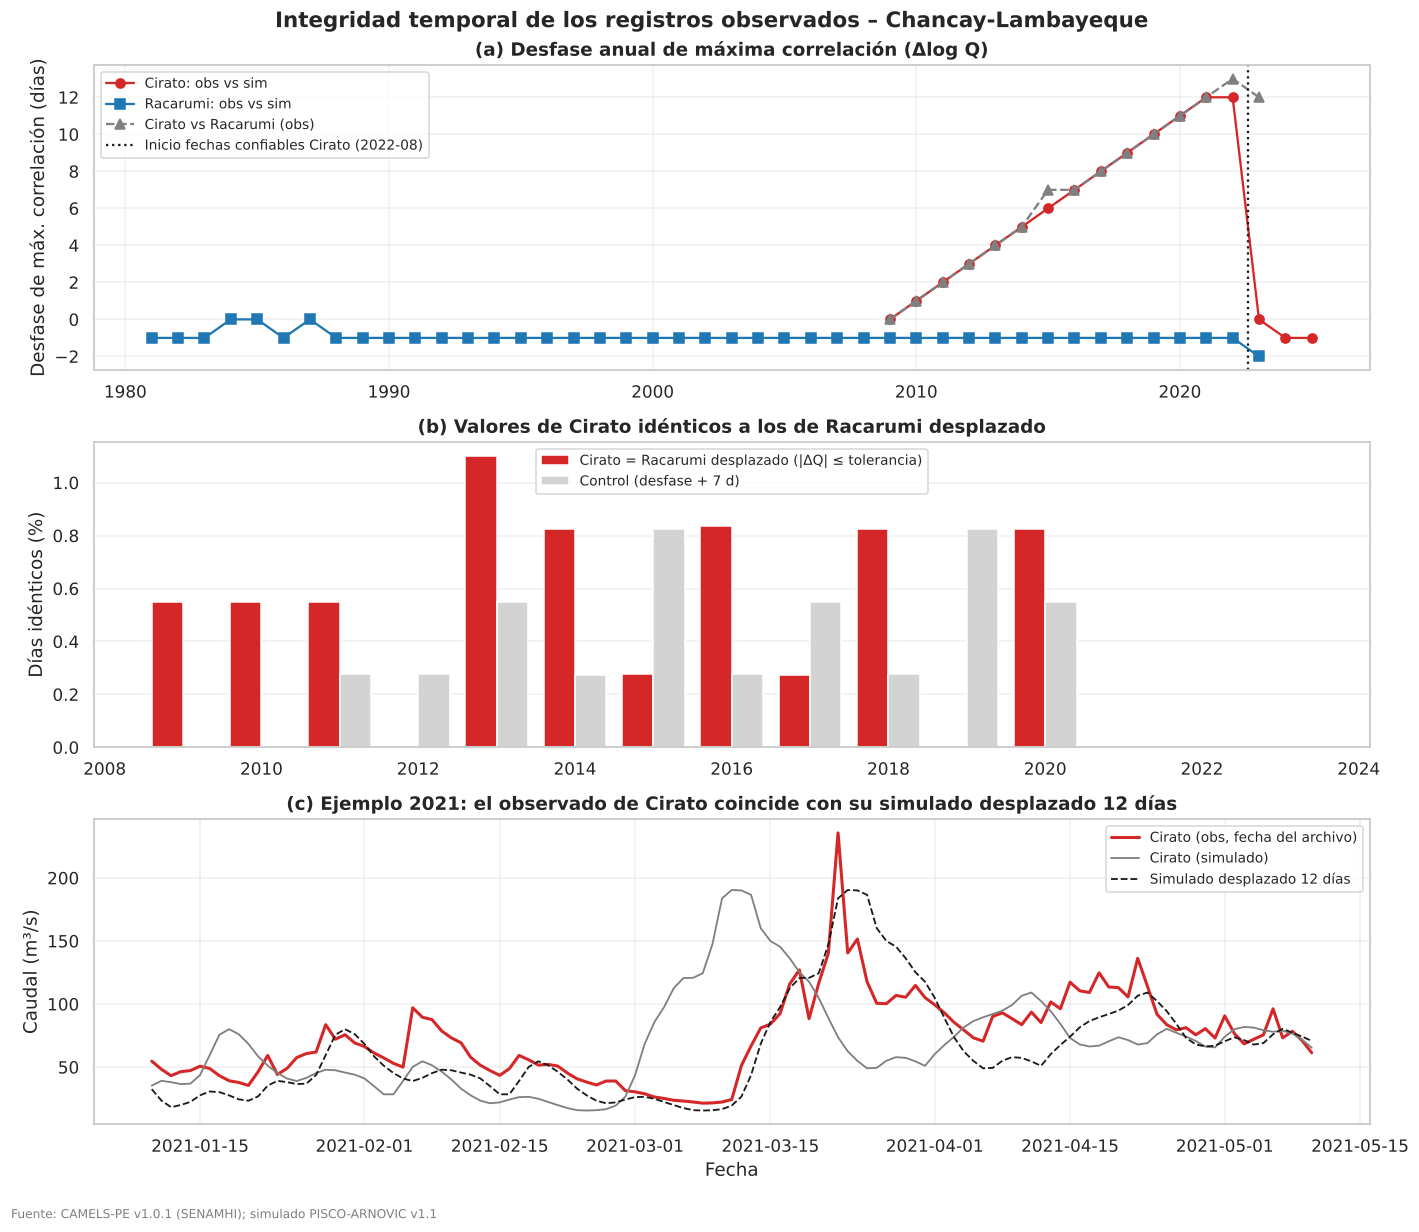

In [10]:
fig, ejes = plt.subplots(3, 1, figsize=(13, 11))
ti = tabla_integridad
ax = ejes[0]
ax.plot(ti.index, ti['desfase obs–sim Cirato (d)'], 'o-', color=COLORES['Cirato'], label='Cirato: obs vs sim')
ax.plot(ti.index, ti['desfase obs–sim Racarumi (d)'], 's-', color=COLORES['Racarumi'], label='Racarumi: obs vs sim')
ax.plot(ti.index, ti['desfase Cirato–Racarumi (d)'], '^--', color='gray', label='Cirato vs Racarumi (obs)')
ax.axvline(inicio_confiable['Cirato'].year + (inicio_confiable['Cirato'].dayofyear / 365), color='k', ls=':',
           label=f"Inicio fechas confiables Cirato ({inicio_confiable['Cirato']:%Y-%m})")
ax.set_ylabel('Desfase de máx. correlación (días)')
ax.set_title('(a) Desfase anual de máxima correlación (Δlog Q)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = ejes[1]
ax.bar(ti.index - 0.2, ti['% idénticos a Racarumi desplazado'], width=0.4, color=COLORES['Cirato'],
       label='Cirato = Racarumi desplazado (|ΔQ| ≤ tolerancia)')
ax.bar(ti.index + 0.2, ti['control: desfase + 7 d (%)'], width=0.4, color='lightgray', label='Control (desfase + 7 d)')
ax.set_ylabel('Días idénticos (%)')
ax.set_title('(b) Valores de Cirato idénticos a los de Racarumi desplazado', fontweight='bold')
ax.legend(fontsize=9); ax.grid(False, axis='x'); ax.grid(True, axis='y', alpha=0.3)

ax = ejes[2]
cols_lag = {n: f'desfase obs–sim {n} (d)' for n in ESTACIONES.values()}
est_ej = max(cols_lag, key=lambda n: ti[cols_lag[n]].max())
anio_ej = int(ti[cols_lag[est_ej]].idxmax())
l_ej = int(ti.loc[anio_ej, cols_lag[est_ej]])
d_ej = series[est_ej]
pico = d_ej['qsim'].loc[str(anio_ej)].idxmax()
x = slice(pico - pd.Timedelta(days=60), pico + pd.Timedelta(days=60))
ax.plot(d_ej['qobs'].loc[x].index, d_ej['qobs'].loc[x], color=COLORES[est_ej], lw=2, label=f'{est_ej} (obs, fecha del archivo)')
ax.plot(d_ej['qsim'].loc[x].index, d_ej['qsim'].loc[x], color='gray', lw=1.2, label=f'{est_ej} (simulado)')
ax.plot(d_ej['qsim'].shift(l_ej).loc[x].index, d_ej['qsim'].shift(l_ej).loc[x], 'k--', lw=1.2,
        label=f'Simulado desplazado {l_ej} días')
ax.set_ylabel('Caudal (m³/s)'); ax.set_xlabel('Fecha')
ax.set_title(f'(c) Ejemplo {anio_ej}: el observado de {est_ej} coincide con su simulado desplazado {l_ej} días', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
fig.suptitle('Integridad temporal de los registros observados – Chancay-Lambayeque', fontsize=14, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig02_integridad_temporal.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:**
- **(a)** El desfase de Cirato frente a su simulado (rojo) y frente a Racarumi (gris) sube casi en línea recta de 2009 a 2022 y cae a 0 en 2023. Racarumi (azul) se mantiene en −1 día durante 42 años.
- **(b)** Las barras de coincidencias exactas (≤ 1.1 %) no se distinguen del control: no hay copia de valores entre estaciones.
- **(c)** En enero–mayo de 2021, el observado de Cirato (rojo) no coincide con su simulado (gris), pero se superpone con el **simulado desplazado 12 días** (negro discontinuo). Por ejemplo, la crecida simulada de inicios de marzo aparece en el observado hacia el 20 de marzo. El observado de ese año está corrido casi dos semanas.

### 2.8 Balance de caudales Racarumi vs Cirato (periodo con fechas confiables)
En los días en que ambas estaciones tienen dato **y** fechas confiables: la razón Q_Racarumi / Q_Cirato, su mediana por año y por mes, y la misma razón con el simulado.
**Por qué:** Cirato drena el 68 % del área de Racarumi (entre ambas está la estación Puente San Carlos). Sin pérdidas ni aportes externos, la razón debería ser ≥ 1 y crecer en época de lluvias (aporta el área intermedia). Una razón < 1 indica pérdidas entre estaciones (infiltración, evaporación, captaciones) o error en alguna curva de descarga; CAMELS-PE registra captaciones superficiales y presas en la cuenca (`surface_adh_*`, `reservoir_*` en 2.1), pero no su operación diaria, por lo que la causa no puede atribuirse con estos datos.

In [11]:
desde = max(inicio_confiable.values())
balance = pd.DataFrame({'CI': q_ci, 'RA': q_ra}).loc[desde:].dropna()
balance = balance[balance['CI'] > 0]
balance['razon'] = balance['RA'] / balance['CI']
print(f"Periodo común con fechas confiables: {balance.index.min().date()} a {balance.index.max().date()} ({len(balance)} días)")
print(f"Razón Q_RA / Q_CI: mediana = {balance['razon'].median():.3f}, P25–P75 = "
      f"{balance['razon'].quantile(.25):.3f}–{balance['razon'].quantile(.75):.3f} | razón de áreas = {area['Racarumi'] / area['Cirato']:.3f}")
print('\nMediana por año:', balance.groupby(balance.index.year)['razon'].median().round(3).to_dict())
mens = pd.DataFrame({'obs': balance.groupby(balance.index.month)['razon'].median(),
                     'sim (1981–2025)': (series['Racarumi']['qsim'] / series['Cirato']['qsim'])
                     .groupby(series['Racarumi'].index.month).median()}).round(2)
print('\nMediana mensual de la razón Q_RA / Q_CI:')
print(mens.T.to_string())


Periodo común con fechas confiables: 2022-08-01 a 2023-08-31 (391 días)
Razón Q_RA / Q_CI: mediana = 1.067, P25–P75 = 0.874–1.269 | razón de áreas = 1.466

Mediana por año: {2022: 0.914, 2023: 1.162}

Mediana mensual de la razón Q_RA / Q_CI:
date               1     2     3     4     5     6     7     8     9     10    11    12
obs              0.89  0.90  1.09  1.19  1.26  1.15  1.54  1.18  0.78  0.91  1.00  0.94
sim (1981–2025)  0.97  1.01  1.03  0.96  0.81  0.83  0.91  0.87  0.91  1.05  1.08  0.94


**Interpretación:**
- **Periodo común confiable (2022-08-01 a 2023-08-31; 391 días):** la mediana de Q_Racarumi/Q_Cirato es **1.07** (P25–P75 0.87–1.27), muy por debajo de la razón de áreas (**1.47**).
  - Mediana mensual: 0.78–1.00 de setiembre a febrero; 1.09–1.54 de marzo a agosto.
  - Por año: 0.91 en 2022 y 1.16 en 2023.
- **Qué significa:** el área intermedia (32 %) apenas añade caudal neto. Es compatible con que entre Cirato y Racarumi se capte o pierda una parte importante del agua. Este análisis no puede atribuir la causa, porque CAMELS-PE no registra la operación diaria de captaciones ni presas.
- **Simulado:** muestra razones de 0.81–1.08, es decir, tampoco "suma" el área intermedia. Es coherente con que cada simulado se ajustó a la distribución del observado de su propia estación.

---
## 3. Valores faltantes

### 3.1 Diagnóstico: cantidad y estructura
Dentro del periodo de registro de cada estación, los vacíos se cuentan y agrupan en rachas aisladas (≤ 3 días), medias (4–30) y largas (> 30); también se revisan las demás variables.
**Por qué:** el tratamiento depende de la estructura (guía del equipo, 3.4, punto 2). En Cirato se reporta además el periodo con fechas confiables (2.7), que es el que se usa en el análisis diario.

In [12]:
def rachas_vacios(s):
    """Longitudes de las rachas de NaN dentro del periodo de registro de una serie."""
    tramo = s.loc[s.first_valid_index():s.last_valid_index()]
    es_nan = tramo.isna().astype(int)
    grupo = (es_nan.diff() != 0).cumsum()
    rachas = es_nan.groupby(grupo).agg(['first', 'size'])
    rachas = rachas[rachas['first'] == 1]
    inicio = tramo.groupby(grupo).apply(lambda x: x.index.min())
    return pd.DataFrame({'inicio': inicio.loc[rachas.index].values, 'dias': rachas['size'].values})

filas, detalle_largos = [], []
for etiqueta, nombre, s in [('Cirato (registro completo)', 'Cirato', series['Cirato']['qobs']),
                            ('Cirato (fechas confiables)', 'Cirato', series['Cirato']['qobs'].loc[inicio_confiable['Cirato']:]),
                            ('Racarumi', 'Racarumi', series['Racarumi']['qobs'])]:
    r = rachas_vacios(s)
    tramo = s.loc[s.first_valid_index():s.last_valid_index()]
    filas.append({'serie': etiqueta, 'días en periodo': len(tramo), 'días vacíos': int(tramo.isna().sum()),
                  '% vacíos': round(100 * tramo.isna().mean(), 2), 'n rachas': len(r),
                  'aisladas (≤3 d)': int((r['dias'] <= 3).sum()), 'medias (4–30 d)': int(r['dias'].between(4, 30).sum()),
                  'largas (>30 d)': int((r['dias'] > 30).sum()), 'días en rachas largas': int(r.loc[r['dias'] > 30, 'dias'].sum()),
                  'racha máxima (d)': int(r['dias'].max()) if len(r) else 0})
    if 'confiables' not in etiqueta:
        for _, fila in r[r['dias'] > 30].iterrows():
            detalle_largos.append({'estación': nombre, 'inicio': fila['inicio'].date(), 'días': fila['dias']})

tabla_vacios_det = pd.DataFrame(filas).set_index('serie')
print(tabla_vacios_det.to_string())
tabla_vacios = tabla_vacios_det.rename(index={'Cirato (fechas confiables)': 'Cirato'}).loc[['Cirato', 'Racarumi']]
tabla_vacios.to_csv(RUTA_TAB / 'tabla_vacios.csv')
print('\nRachas largas (> 30 días):')
print(pd.DataFrame(detalle_largos).to_string(index=False))
print('\nOtras variables (Racarumi; mismo patrón en ambas): vacíos y periodo con dato')
otras = series['Racarumi'].drop(columns=['flow_obs', 'qobs', 'qsim'])
print(pd.DataFrame({'vacíos': otras.isna().sum(),
                    'primer dato': otras.apply(lambda c: c.first_valid_index().date()),
                    'último dato': otras.apply(lambda c: c.last_valid_index().date())}).to_string())

                            días en periodo  días vacíos  % vacíos  n rachas  aisladas (≤3 d)  medias (4–30 d)  largas (>30 d)  días en rachas largas  racha máxima (d)
serie                                                                                                                                                                  
Cirato (registro completo)             6243           36      0.58        23               22                1               0                      0                12
Cirato (fechas confiables)             1249           13      1.04         2                1                1               0                      0                12
Racarumi                              15583           50      0.32        26               21                5               0                      0                 7

Rachas largas (> 30 días):
Empty DataFrame
Columns: []
Index: []

Otras variables (Racarumi; mismo patrón en ambas): vacíos y periodo con dato
          vacíos

**Interpretación:**
- **Cirato, registro completo:** 0.58 % de vacíos, pero esa cifra engaña porque el problema es de fechas (2.7).
- **Cirato, periodo confiable:** **1.04 %** de vacíos (13 de 1 249 días), en 2 rachas (máximo 12 días).
- **Racarumi:** solo **0.32 %** de vacíos (50 de 15 583 días), sin bloques largos (racha máxima de 7 días). Es una serie excepcionalmente completa.
- **Otras variables:** la ETP termina en 2016-12-31 y la temperatura en 2020-12-31. En el periodo confiable de Cirato no hay ETP ni temperatura.

### 3.2 Mapa de calor de disponibilidad
Fracción de días con dato observado por mes y estación (1981–2025) con `sns.heatmap` (Lab4_2); se añade una fila para Cirato con fechas confiables.
**Por qué:** muestra el periodo común y los bloques vacíos.

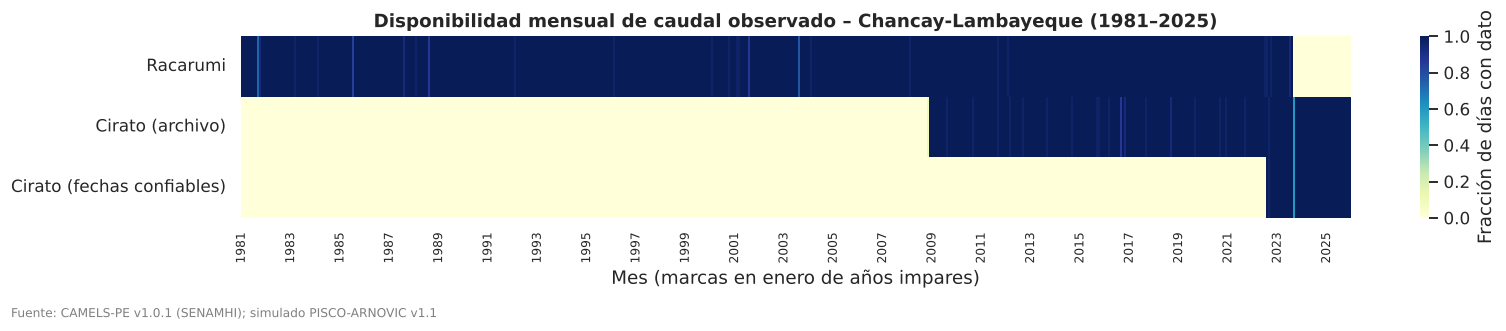

In [13]:
disp = pd.DataFrame({
    'Racarumi': series['Racarumi']['flow_obs'].notna(),
    'Cirato (archivo)': series['Cirato']['flow_obs'].notna(),
    'Cirato (fechas confiables)': series['Cirato']['flow_obs'].notna() & (series['Cirato'].index >= inicio_confiable['Cirato']),
})
disp_mensual = disp.resample('MS').mean().T
fig, ax = plt.subplots(figsize=(15, 2.8))
sns.heatmap(disp_mensual, cmap='YlGnBu', vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'Fracción de días con dato'})
etiquetas = [f'{c.year}' if (c.month == 1 and c.year % 2 == 1) else '' for c in disp_mensual.columns]
ax.set_xticks(np.arange(len(etiquetas)) + 0.5)
ax.set_xticklabels(etiquetas, rotation=90, fontsize=8)
ax.set_xlabel('Mes (marcas en enero de años impares)'); ax.set_ylabel('')
ax.set_title('Disponibilidad mensual de caudal observado – Chancay-Lambayeque (1981–2025)', fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig01_disponibilidad.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:** Racarumi está prácticamente completa de 1981 a agosto de 2023 y termina allí en CAMELS-PE. Cirato "del archivo" parece completa desde 2009, pero **con fechas confiables solo cubre de agosto de 2022 en adelante**. El solapamiento útil de ambas estaciones es de agosto de 2022 a agosto de 2023.

### 3.3 Criterio de tratamiento (fijado antes de modelar)
| Uso | Tratamiento | Justificación |
|---|---|---|
| Métricas obs vs sim (secciones 5 y 7) | **Sin imputación**: solo fechas con observado y simulado válidos | Rellenar el observado introduciría información del modelo en la referencia. |
| Cirato antes del inicio de fechas confiables (2.7) | **Se excluye del análisis diario**; se usa solo en la sensibilidad de 5.2 para mostrar el efecto del error | No es un vacío sino un error de fechas/duplicación; realinear exigiría suponer el desfase día a día. |
| Agregados mensuales | Mes válido solo si faltan ≤ 10 días y no hay ≥ 5 días seguidos faltantes | WMO-No. 1203 (2017), §4.4.1. |
| Autocorrelación y *flashiness* | Sin imputación; solo pares de días consecutivos válidos | `autocorr` y `diff` ignoran pares incompletos. |
| Descomposición (serie continua) | Interpolación lineal solo en vacíos ≤ 3 días; tramo continuo más largo | Guía del equipo (3.4, punto 2) y Ses6a. |
| Bloques > 30 días | No se imputan | Ningún relleno reproduce crecidas no observadas. |

La interpolación ≤ 3 días se aplica a una copia y se mide su efecto en la media, la desviación y el P90.

In [14]:
def interpolar_cortos(s, max_dias=3):
    """Interpola linealmente solo rachas de NaN de longitud ≤ max_dias."""
    es_nan = s.isna()
    grupo = (es_nan != es_nan.shift()).cumsum()
    largo = es_nan.groupby(grupo).transform('sum')
    candidata = s.interpolate(method='time', limit_area='inside')
    return s.where(~(es_nan & (largo <= max_dias)), candidata)

efecto = []
for nombre, df in series.items():
    s0 = df['qobs'].loc[inicio_confiable[nombre]:]
    s1 = interpolar_cortos(s0)
    efecto.append({'estación': nombre, 'días imputados': int(s1.notna().sum() - s0.notna().sum()),
                   'media antes': s0.mean(), 'media después': s1.mean(), 'desv. antes': s0.std(), 'desv. después': s1.std(),
                   'P90 antes': s0.quantile(.9), 'P90 después': s1.quantile(.9)})
tabla_efecto = pd.DataFrame(efecto).set_index('estación').round(3)
tabla_efecto['cambio media (%)'] = (100 * (tabla_efecto['media después'] / tabla_efecto['media antes'] - 1)).round(3)
tabla_efecto

,días imputados,media antes,media después,desv. antes,desv. después,P90 antes,P90 después,cambio media (%)
estación,,,,,,,,
Cirato,1,35.165,35.142,36.028,36.022,85.698,85.677,-0.065
Racarumi,25,35.612,35.623,38.906,38.933,88.186,88.285,0.031


**Interpretación:** la interpolación (≤ 3 días) rellena 1 día en Cirato y 25 en Racarumi, con cambios de media de −0.07 % y +0.03 % y cambios de desviación y P90 menores a 0.3 %. El efecto es despreciable. La versión interpolada solo se usa en la descomposición (8.3); las métricas obs–sim no la usan.

---
## 4. Outliers: errores de medición vs. crecidas reales

Principio: **una crecida no se elimina por ser extrema**; solo se elimina un dato con evidencia de error.
1. **Pruebas físicas:** negativos, ceros, líneas planas ≥ 7 días, saltos > 4σ.
2. **Criterios estadísticos** (solo señalan candidatos): IQR (1.5·RIC, Lab4_2) y z robusto MAD (|z| > 3.5; Iglewicz y Hoaglin, 1993) sobre **log(Q + ε)** y sobre su variación diaria Δlog (3·RIC).
3. **Corroboración física** (decide): (a) **caída aislada**: baja a menos de la mitad del promedio de sus vecinos y se recupera al día siguiente; (b) **pico aislado sin lluvia**: sube a más del doble y revierte, con lluvia de 3 días < P25; (c) **nivel bajo extremo**: valor marcado a la vez por IQR y MAD y por debajo de la mediana. En (a) y (b) se exige además que los dos vecinos estén dentro de un factor 2 entre sí (el día siguiente **vuelve al nivel previo**): en un río de respuesta rápida, un día bajo seguido del inicio de una crecida no es una "recuperación".

**Sobre los caudales bajos:** en esta cuenca los caudales de estiaje bajos son físicamente posibles (`aridity` ≈ 0.9–1.1, `baseflow_index` ≈ 0.52–0.55 y captaciones aguas arriba; ver 2.1), así que un valor bajo no es, por sí solo, evidencia de error. Por eso la regla (c) exige que **ambos** criterios robustos lo marquen.

### 4.1 Pruebas físicas
Conteo de negativos, ceros, la racha más larga de valores idénticos (con la lista de las ≥ 7 días) y los saltos > 4σ, en el periodo con fechas confiables.

In [15]:
filas, planas = [], []
for nombre, df in series.items():
    q = df['qobs'].loc[inicio_confiable[nombre]:]
    v = q.dropna()
    grupo_igual = (v.diff() != 0).cumsum()
    tam = v.groupby(grupo_igual).transform('size')
    for g in grupo_igual[tam >= 7].unique():
        tramo = v[grupo_igual == g]
        planas.append({'estación': nombre, 'inicio': tramo.index[0].date(), 'días': len(tramo), 'Q (m³/s)': round(tramo.iloc[0], 3)})
    salto = q.diff().abs()
    filas.append({'estación': nombre, 'negativos': int((q < 0).sum()), 'ceros': int((q == 0).sum()),
                  'racha máx. de valores idénticos (d)': int(tam.max()),
                  'rachas planas ≥ 7 d': int(len(grupo_igual[tam >= 7].unique())),
                  'saltos > 4σ': int((salto > 4 * q.diff().std()).sum()), 'mín (m³/s)': round(q.min(), 3)})
display(pd.DataFrame(filas).set_index('estación'))
print('Rachas de valores idénticos ≥ 7 días:')
print(pd.DataFrame(planas).to_string(index=False))

,negativos,ceros,racha máx. de valores idénticos (d),rachas planas ≥ 7 d,saltos > 4σ,mín (m³/s)
estación,,,,,,
Cirato,0,0,4,0,11,5.056
Racarumi,0,5,3,0,204,0.000


Rachas de valores idénticos ≥ 7 días:
Empty DataFrame
Columns: []
Index: []


**Interpretación** (periodos confiables):
- **Sin negativos ni líneas planas largas** (racha máxima de 3–4 días).
- **5 ceros en Racarumi:**
  - 2011-07-29 y 2011-11-04;
  - **2022-12-29, 2023-01-06 y 2023-02-22**, estos tres en plena época de lluvias.
- **Saltos > 4σ:** 204 en Racarumi frente a 11 en Cirato. Es esperable en un río de respuesta rápida con 42 años de registro, y se analiza con los criterios de 4.2–4.3.

### 4.2 Criterios estadísticos: IQR vs. z robusto (MAD)
Ambos criterios se aplican sobre log(Q + ε) (nivel) y sobre Δlog (cambio diario).

In [16]:
def marcas_iqr(x, k=1.5):
    """True donde x cae fuera de [Q1 − k·RIC, Q3 + k·RIC]."""
    q1, q3 = x.quantile([.25, .75])
    ric = q3 - q1
    return (x < q1 - k * ric) | (x > q3 + k * ric)

def z_robusto(x):
    """z modificado de Iglewicz y Hoaglin (1993): 0.6745·(x − mediana)/MAD."""
    mediana = x.median()
    mad = (x - mediana).abs().median()
    return 0.6745 * (x - mediana) / mad

candidatos, filas = {}, []
for nombre, df in series.items():
    q = df['qobs'].loc[inicio_confiable[nombre]:]
    lq = log_q(q)
    dl = lq.diff()
    marcas = pd.DataFrame({'iqr_nivel': marcas_iqr(lq), 'mad_nivel': z_robusto(lq).abs() > 3.5,
                           'iqr_cambio': marcas_iqr(dl, k=3.0), 'mad_cambio': z_robusto(dl).abs() > 3.5}
                          ).where(q.notna(), False).astype(bool)
    candidatos[nombre] = marcas
    filas.append({'estación': nombre, 'ε (m³/s)': round(q.mean() / 100, 3),
                  'IQR nivel': int(marcas['iqr_nivel'].sum()), 'MAD nivel': int(marcas['mad_nivel'].sum()),
                  'ambos nivel': int((marcas['iqr_nivel'] & marcas['mad_nivel']).sum()),
                  'nivel bajo (IQR)': int((marcas['iqr_nivel'] & (lq < lq.median())).sum()),
                  'IQR cambio (3·RIC)': int(marcas['iqr_cambio'].sum()), 'MAD cambio': int(marcas['mad_cambio'].sum()),
                  'ambos cambio': int((marcas['iqr_cambio'] & marcas['mad_cambio']).sum())})
pd.DataFrame(filas).set_index('estación')

,ε (m³/s),IQR nivel,MAD nivel,ambos nivel,nivel bajo (IQR),IQR cambio (3·RIC),MAD cambio,ambos cambio
estación,,,,,,,,
Cirato,0.352,0,0,0,0,82,122,82
Racarumi,0.356,5,5,5,5,343,834,343


**Interpretación:**
- **Nivel:** en Racarumi, IQR y MAD marcan los **mismos 5 valores**, todos bajos: son los 5 ceros de 4.1. Cirato no tiene marcas. Ninguna crecida queda marcada en nivel.
- **Cambio diario:** los criterios marcan muchos puntos (343 con IQR y 834 con MAD en Racarumi). Ningún criterio separa por sí solo errores de crecidas, por eso decide la corroboración física (4.3).

### 4.3 Corroboración y decisión
Con las reglas (a)–(c) se construye la bandera final de error, con la tabla de puntos eliminados y su motivo.

In [17]:
banderas, eliminados = {}, []
for nombre, df in series.items():
    q = df['qobs'].where(df.index >= inicio_confiable[nombre])
    lq = log_q(q)
    z_c = z_robusto(lq.diff())
    desvio = lq - (lq.shift(1) + lq.shift(-1)) / 2
    vecinos_similares = (lq.shift(-1) - lq.shift(1)).abs() < np.log(2)     # el día siguiente vuelve al nivel previo
    aislado = ((z_c.abs() > 3.5) & (z_c.shift(-1).abs() > 3.5) &
               (np.sign(z_c) != np.sign(z_c.shift(-1))) & (desvio.abs() > np.log(2)) & vecinos_similares)
    lluvia3 = df['prec'].rolling(3).sum()
    seco = lluvia3 < lluvia3.quantile(0.25)
    m = candidatos[nombre].reindex(df.index).fillna(False)
    reglas = pd.DataFrame({'caida_aislada': aislado & (desvio < 0),
                           'pico_aislado_sin_lluvia': aislado & (desvio > 0) & seco,
                           'nivel_bajo_extremo': m['iqr_nivel'] & m['mad_nivel'] & (lq < lq.median())}).fillna(False)
    error = reglas.any(axis=1)
    banderas[nombre] = error
    for fecha in error[error].index:
        eliminados.append({'estación': nombre, 'fecha': fecha.date(), 'Q obs (m³/s)': round(q.loc[fecha], 2),
                           'Q día anterior': round(q.shift(1).loc[fecha], 2), 'Q día siguiente': round(q.shift(-1).loc[fecha], 2),
                           'Q sim (m³/s)': round(df.loc[fecha, 'qsim'], 2), 'lluvia 3 d (mm)': round(lluvia3.loc[fecha], 1),
                           'motivo': ', '.join(reglas.columns[reglas.loc[fecha]])})
    # Candidatos aislados que se CONSERVAN (picos con lluvia): se listan para transparencia
    conservados = aislado & (desvio > 0) & ~seco
    print(f"{nombre}: picos aislados con lluvia conservados = {int(conservados.sum())}")

tabla_eliminados = pd.DataFrame(eliminados)
tabla_eliminados.to_csv(RUTA_TAB / 'tabla_outliers_eliminados.csv', index=False)
print('Puntos eliminados por estación:', tabla_eliminados.groupby('estación').size().to_dict() if len(tabla_eliminados) else {})
tabla_eliminados

Cirato: picos aislados con lluvia conservados = 1
Racarumi: picos aislados con lluvia conservados = 16
Puntos eliminados por estación: {'Racarumi': 15}


,estación,fecha,Q obs (m³/s),Q día anterior,Q día siguiente,Q sim (m³/s),lluvia 3 d (mm),motivo
0,Racarumi,1983-06-18,8.94,37.64,26.45,87.04,6.3,caida_aislada
1,Racarumi,1991-08-30,0.88,4.02,7.77,1.83,0.2,caida_aislada
2,Racarumi,1991-08-31,7.77,0.88,2.08,1.83,0.1,pico_aislado_sin_lluvia
3,Racarumi,1991-11-16,8.94,4.02,2.95,6.84,0.2,pico_aislado_sin_lluvia
4,Racarumi,1994-08-27,2.11,4.46,4.79,5.83,0.0,caida_aislada
5,Racarumi,1995-08-07,2.24,6.43,4.49,6.54,0.2,caida_aislada
6,Racarumi,2002-07-08,5.14,13.68,13.24,16.82,5.7,caida_aislada
7,Racarumi,2011-07-29,0.00,7.93,7.96,7.88,1.1,"caida_aislada, nivel_bajo_extremo"
8,Racarumi,2011-11-04,0.00,7.17,11.95,13.70,7.0,"caida_aislada, nivel_bajo_extremo"
9,Racarumi,2013-08-29,2.90,9.19,7.08,9.90,0.2,caida_aislada


**Interpretación:** se eliminan **15 valores, todos en Racarumi**; Cirato no tiene errores en su periodo confiable.
- **Los 5 ceros:** cumplen a la vez "caída aislada" y "nivel bajo extremo". Por ejemplo, el **2023-02-22** marca 0 entre 78 y 122 m³/s, con 67 mm de lluvia en 3 días y un simulado de 108 m³/s.
- **8 caídas aisladas más:** por ejemplo, 1983-06-18 (8.9 m³/s entre 37.6 y 26.5) y 2018-04-29 (28.8 entre 55.4 y 98.0).
- **2 picos aislados sin lluvia:** 1991-08-31 y 1991-11-16, con lluvia de 0.1–0.2 mm.

En agosto de 1991 se eliminan dos días seguidos (0.88 y luego 7.77 m³/s), un tramo claramente erróneo. **Se conservan 16 picos aislados con lluvia** en Racarumi y 1 en Cirato.

### 4.4 Consistencia entre estaciones (diagnóstico)
Con el balance de 2.8 se marcan los días con Q_RA / Q_CI fuera de [0.5, 2] y se ubican en el tiempo junto a ambos hidrogramas.
**Por qué:** no indica cuál estación falla; con un área intermedia del 32 % y posibles captaciones el rango esperable es amplio, por lo que se usa solo como diagnóstico.

Días fuera de [0.5, 2]: 19 de 391 (4.9 %)
Por año-mes: {(2022, 8): 1, (2022, 9): 6, (2022, 10): 1, (2022, 12): 1, (2023, 1): 1, (2023, 2): 1, (2023, 3): 6, (2023, 4): 1, (2023, 8): 1}
Fuera de rango por régimen: razón < 0.5 en días con Q_CI < P30: 0 | razón > 2 en días con Q_CI > P70: 2


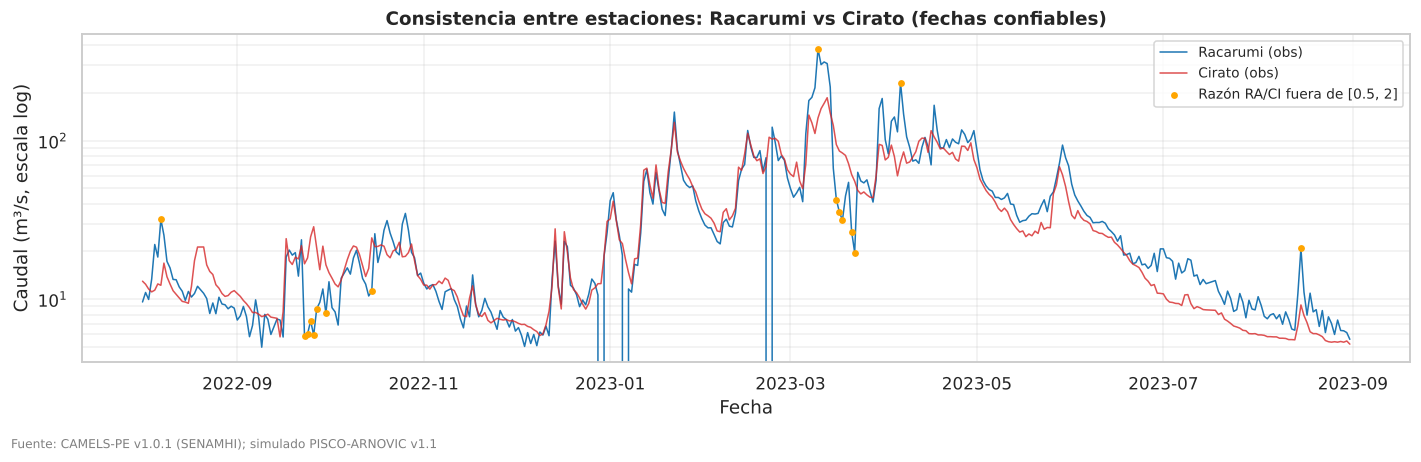

In [18]:
balance['fuera_rango'] = ~balance['razon'].between(0.5, 2)
print(f"Días fuera de [0.5, 2]: {balance['fuera_rango'].sum()} de {len(balance)} ({100 * balance['fuera_rango'].mean():.1f} %)")
fr = balance[balance['fuera_rango']]
print('Por año-mes:', fr.groupby([fr.index.year, fr.index.month]).size().to_dict())
print('Fuera de rango por régimen: razón < 0.5 en días con Q_CI < P30:',
      int(((balance['razon'] < 0.5) & (balance['CI'] < balance['CI'].quantile(.3))).sum()),
      '| razón > 2 en días con Q_CI > P70:', int(((balance['razon'] > 2) & (balance['CI'] > balance['CI'].quantile(.7))).sum()))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(balance.index, balance['RA'], color=COLORES['Racarumi'], lw=1, label='Racarumi (obs)')
ax.plot(balance.index, balance['CI'], color=COLORES['Cirato'], lw=1, alpha=0.8, label='Cirato (obs)')
ax.scatter(fr.index, fr['RA'], color='orange', s=12, zorder=5, label='Razón RA/CI fuera de [0.5, 2]')
ax.set_yscale('log')
ax.set_ylabel('Caudal (m³/s, escala log)'); ax.set_xlabel('Fecha')
ax.set_title('Consistencia entre estaciones: Racarumi vs Cirato (fechas confiables)', fontweight='bold')
ax.legend(loc='upper right', fontsize=9); ax.grid(True, which='both', alpha=0.3)
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig03_consistencia_vecinas.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:** en el periodo común confiable solo el **4.9 %** de los días (19 de 391) tiene Q_Racarumi/Q_Cirato fuera de [0.5, 2]. Las dos estaciones son coherentes la mayor parte del tiempo. La figura muestra dos tipos de desajuste:
- **Los ceros de Racarumi** (líneas verticales en enero–febrero de 2023), eliminados en 4.3.
- **Mediados de marzo de 2023:** tras el pico, Racarumi cae de **218 a 67 m³/s en un día** (2023-03-14 → 15) y llega a ~20 m³/s el 22 de marzo, mientras Cirato, aguas arriba, sigue con caudales mayores. Una caída así es compatible con una derivación aguas arriba de Racarumi o con un problema de medición durante la crecida. No hay evidencia para eliminarlo, así que se conserva y se declara.

### 4.5 Serie depurada final
Los errores de 4.3 pasan a NaN y se crea el conjunto **pareado** (obs y sim válidos el mismo día) de cada estación; para Cirato solo desde el inicio de fechas confiables. Se guarda también el pareado de Cirato con el **registro completo sin corregir**, para la sensibilidad de 5.2.

In [19]:
pareados = {}
for nombre, df in series.items():
    df['qobs_dep'] = df['qobs'].mask(banderas[nombre].reindex(df.index).fillna(False))
    df.loc[df.index < inicio_confiable[nombre], 'qobs_dep'] = np.nan
    p = (df[['qobs_dep', 'qsim', 'prec']].dropna(subset=['qobs_dep', 'qsim'])
         .rename(columns={'qobs_dep': 'obs', 'qsim': 'sim'}))
    pareados[nombre] = p
    print(f"{nombre:9s}: {len(p):5d} días pareados ({p.index.min().date()} a {p.index.max().date()}); "
          f"eliminados por error: {int(banderas[nombre].sum())}")

ci = series['Cirato']
pareado_ci_completo = (ci[['qobs', 'qsim', 'prec']].dropna(subset=['qobs', 'qsim'])
                       .rename(columns={'qobs': 'obs', 'qsim': 'sim'}))
print(f"Cirato, registro completo SIN corregir (solo para 5.2): {len(pareado_ci_completo)} días "
      f"({pareado_ci_completo.index.min().date()} a {pareado_ci_completo.index.max().date()})")

Cirato   :  1236 días pareados (2022-08-01 a 2025-12-31); eliminados por error: 0
Racarumi : 15518 días pareados (1981-01-01 a 2023-08-31); eliminados por error: 15
Cirato, registro completo SIN corregir (solo para 5.2): 6207 días (2008-11-28 a 2025-12-31)


**Interpretación:**
- **Cirato:** quedan **1 236 días pareados** (2022-08-01 a 2025-12-31).
- **Racarumi:** quedan **15 518** (1981-01-01 a 2023-08-31), unas 12 veces más.
- **Cirato sin corregir:** el registro completo (6 207 días) se conserva aparte, solo para mostrar en 5.2 cuánto distorsiona el error de fechas.

Las métricas de Cirato dependen de unos 3 años hidrológicos.

---
## 5. Observado vs. simulado

### 5.1 Métricas globales diarias y mensuales
Sobre fechas pareadas: NSE, KGE (r, α, β), PBIAS, RMSE, NSE-log, BE frente a la climatología mensual del observado, FHV y FMS; NSE/PBIAS mensuales con meses válidos según la regla OMM; IC 95 % del KGE y NSE diarios por bootstrap de bloques mensuales.
**Por qué cada métrica:** NSE es la métrica clásica y base de Moriasi et al. (2007); KGE descompone el error en correlación (r), variabilidad (α) y sesgo (β) (Gupta et al., 2009), y su referencia "sin habilidad" es −0.41, no 0 (Knoben et al., 2019); NSE-log pondera caudales bajos; BE responde si el modelo aporta más que el ciclo estacional (Schaefli y Gupta, 2007); FHV/FMS describen sesgos de la curva de duración (Yilmaz et al., 2008).

In [20]:
def climatologia_mensual(p):
    """Benchmark: media del observado de cada mes calendario, asignada a cada día."""
    return p.index.month.map(p['obs'].groupby(p.index.month).mean())

def serie_mensual_valida(s_diaria):
    """Media mensual solo para meses que cumplen la regla OMM (≤ 10 faltantes y < 5 consecutivos)."""
    meses = []
    for (anio, mes), g in s_diaria.groupby([s_diaria.index.year, s_diaria.index.month]):
        dias_mes = pd.Timestamp(anio, mes, 1).days_in_month
        g = g.reindex(pd.date_range(pd.Timestamp(anio, mes, 1), periods=dias_mes, freq='D'))
        nan = g.isna().astype(int)
        consec = nan.groupby((nan.diff() != 0).cumsum()).transform('sum').where(nan == 1, 0).max()
        if nan.sum() <= 10 and consec < 5:
            meses.append((pd.Timestamp(anio, mes, 1), g.mean()))
    return pd.Series(dict(meses), dtype=float)

def metricas(p):
    """Métricas diarias para un DataFrame pareado con columnas obs y sim."""
    k, r, a, b = kge(p['obs'], p['sim'])
    return {'n días': len(p), 'NSE': nse(p['obs'], p['sim']), 'KGE': k, 'r': r, 'α': a, 'β': b,
            'PBIAS (%)': pbias(p['obs'], p['sim']), 'RMSE (m³/s)': rmse(p['obs'], p['sim']),
            'NSE-log': nse_log(p['obs'], p['sim']),
            'BE (vs clim. mensual)': eficiencia_benchmark(p['obs'], p['sim'], climatologia_mensual(p)),
            'FHV (%)': fhv(p['obs'], p['sim']), 'FMS (%)': fms(p['obs'], p['sim'])}

filas, mensuales = [], {}
for nombre, p in pareados.items():
    fila = {'estación': nombre, **metricas(p)}
    obs_m = serie_mensual_valida(series[nombre]['qobs_dep'].loc[inicio_confiable[nombre]:])
    pm = pd.DataFrame({'obs': obs_m, 'sim': series[nombre]['qsim'].resample('MS').mean()}).dropna()
    mensuales[nombre] = pm
    fila.update({'n meses válidos': len(pm), 'NSE mensual': nse(pm['obs'], pm['sim']), 'PBIAS mensual (%)': pbias(pm['obs'], pm['sim'])})
    boot_kge = bootstrap_bloques_mensuales(p, lambda d: kge(d['obs'], d['sim'])[0])
    boot_nse = bootstrap_bloques_mensuales(p, lambda d: nse(d['obs'], d['sim']))
    fila['KGE IC95'] = f"[{np.percentile(boot_kge, 2.5):.2f}, {np.percentile(boot_kge, 97.5):.2f}]"
    fila['NSE IC95'] = f"[{np.percentile(boot_nse, 2.5):.2f}, {np.percentile(boot_nse, 97.5):.2f}]"
    filas.append(fila)
tabla_metricas = pd.DataFrame(filas).set_index('estación')
tabla_metricas.to_csv(RUTA_TAB / 'tabla_metricas_obs_sim.csv')
tabla_metricas.T.round(3)

estación,Cirato,Racarumi
n días,1236,15518
NSE,0.728434,0.732773
KGE,0.773445,0.867209
r,0.894791,0.867595
α,1.105714,1.008755
β,1.170536,1.005064
PBIAS (%),17.053626,0.506449
RMSE (m³/s),18.767481,20.114841
NSE-log,0.798561,0.820668
BE (vs clim. mensual),0.454516,0.523767


**Interpretación:**

**Racarumi (1981–2023): el simulado es bueno.**
- NSE = **0.73** (IC 0.68–0.78), KGE = **0.87** (IC 0.83–0.88) y BE = **0.52**: supera claramente a la climatología mensual.
- NSE mensual = 0.85, |PBIAS| < 1 %.
- α y β ≈ 1.01 por el mapeo de cuantiles (2.6). Lo que mide habilidad es r = 0.87 y el BE positivo.

**Cirato (fechas confiables): también buena sincronía, pero con sobreestimación.**
- NSE = **0.73** (IC 0.55–0.83) y r = 0.89.
- **Sobreestima el volumen en 17 %** (β = 1.17; PBIAS mensual +16.9 %), con KGE = 0.77 y BE = 0.45.
- La curva de duración simulada queda por encima de la observada en casi todo su rango (5.5): el simulado de Cirato se ajustó a una distribución que no es la del periodo reciente.
- NSE-log = 0.80–0.82 en ambas: los caudales bajos y medios están bien representados.

### 5.2 Pruebas de sensibilidad
Las métricas se recalculan (a) de Cirato con el **registro completo sin corregir** frente al periodo con fechas confiables; (b) de Racarumi dentro (1981–2020) y fuera (2021–2025) de la ventana de calibración de PISCO-ARNOVIC, y en el mismo periodo que Cirato confiable (comparación justa entre estaciones).
**Por qué:** (a) cuantifica cuánto distorsiona el error de fechas; (b) si el desempeño cae fuera de la ventana de calibración, las métricas 1981–2020 estarían infladas; (c) como el periodo confiable de Cirato es corto, se repite sin el mes de mayor error cuadrático para saber si un solo evento domina las métricas.

In [21]:
p_ra = pareados['Racarumi']
casos = {
    'Cirato – registro completo sin corregir': pareado_ci_completo,
    'Cirato – fechas confiables': pareados['Cirato'],
    'Racarumi – completo': p_ra,
    'Racarumi – 1981–2020 (ventana calibración)': p_ra.loc[:'2020-12-31'],
    'Racarumi – 2021–2025 (fuera de ventana)': p_ra.loc['2021-01-01':],
    'Racarumi – mismo periodo que Cirato confiable': p_ra.loc[pareados['Cirato'].index.min():],
}
def sin_mes_mayor_error(p):
    """Quita el mes calendario con mayor suma de errores cuadráticos (sim − obs)²."""
    mes = ((p['sim'] - p['obs']) ** 2).groupby(p.index.to_period('M')).sum().idxmax()
    return p[p.index.to_period('M') != mes], str(mes)
p_sm, mes_sm = sin_mes_mayor_error(pareados['Cirato'])
casos[f'Cirato – fechas confiables sin {mes_sm} (mes de mayor error)'] = p_sm
p_sm, mes_sm = sin_mes_mayor_error(p_ra.loc[pareados['Cirato'].index.min():])
casos[f'Racarumi – mismo periodo sin {mes_sm} (mes de mayor error)'] = p_sm
tabla_sens = pd.DataFrame({k: metricas(v) for k, v in casos.items()}).T
tabla_sens.to_csv(RUTA_TAB / 'tabla_sensibilidad.csv')
tabla_sens[['n días', 'NSE', 'KGE', 'r', 'α', 'β', 'PBIAS (%)', 'NSE-log', 'BE (vs clim. mensual)']].round(3)

,n días,NSE,KGE,r,α,β,PBIAS (%),NSE-log,BE (vs clim. mensual)
Cirato – registro completo sin corregir,6207.0,0.546,0.771,0.772,0.995,1.002,0.194,0.634,0.043
Cirato – fechas confiables,1236.0,0.728,0.773,0.895,1.106,1.171,17.054,0.799,0.455
Racarumi – completo,15518.0,0.733,0.867,0.868,1.009,1.005,0.506,0.821,0.524
Racarumi – 1981–2020 (ventana calibración),14554.0,0.738,0.869,0.870,1.007,1.009,0.943,0.819,0.534
Racarumi – 2021–2025 (fuera de ventana),964.0,0.666,0.831,0.841,1.040,0.956,-4.417,0.815,0.293
Racarumi – mismo periodo que Cirato confiable,389.0,0.551,0.659,0.854,1.253,1.175,17.549,0.819,0.016
Cirato – fechas confiables sin 2023-04 (mes de mayor error),1206.0,0.758,0.804,0.899,1.069,1.153,15.337,0.794,0.535
Racarumi – mismo periodo sin 2023-03 (mes de mayor error),358.0,0.742,0.724,0.924,1.238,1.116,11.620,0.843,-0.076


**Interpretación:**
1. **El error de fechas de Cirato degrada las métricas, pero no las anula.** Con el registro sin corregir, NSE = 0.55 (frente a 0.73 corregido) y BE = 0.04 (frente a 0.45). Con desfases de hasta 12 días el simulado apenas supera a la climatología; **unas métricas moderadas no prueban que la serie esté bien fechada**.
2. **Racarumi es estable entre periodos.** NSE 0.74 en 1981–2020 frente a 0.67 en 2021–2023, con BE de 0.53 y 0.29: el simulado mantiene habilidad fuera de la ventana de calibración, aunque menor.
3. **En el periodo corto de Cirato confiable, Racarumi empeora:** NSE = 0.55, BE = 0.02, PBIAS +17.5 % y α = 1.25. Sin marzo de 2023 (su mes de mayor error) sube a NSE = 0.74, pero el BE (−0.08) y el sesgo (+11.6 %) se mantienen. El periodo reciente es más difícil para el simulado también en Racarumi.
4. **Sin el mes de mayor error (abril de 2023), Cirato mejora poco** (NSE 0.76, BE 0.54): su sobreestimación (+15 %) no depende de un solo evento.

### 5.3 Homogeneidad de Racarumi (registro 1981–2025)
Por año (≥ 330 días observados): razón media(obs)/media(sim) e índice RB del observado; tendencia monótona con la correlación de Spearman frente al año (Lab3_2; equivalente en espíritu a Mann-Kendall) y comparación de 1981–2020 con 2021–2025 con Mann-Whitney.
**Por qué:** un cambio de curva de descarga, de sección o de método de lectura produciría un quiebre en el nivel del observado respecto del simulado, o en su variabilidad diaria. Se usan años para reducir la autocorrelación; Mann-Whitney porque n es pequeño y no se supone normalidad.

In [22]:
ra = series['Racarumi']
cuenta = ra['qobs_dep'].groupby(ra.index.year).count()
anios_ok = cuenta[cuenta >= 330].index
razon_anual = (ra['qobs_dep'].groupby(ra.index.year).mean() /
               ra['qsim'].where(ra['qobs_dep'].notna()).groupby(ra.index.year).mean()).loc[anios_ok]
rb_anual = pd.Series({a: richards_baker(ra['qobs_dep'].loc[str(a)]) for a in anios_ok})
print('Razón anual media(obs)/media(sim) y RB anual del observado (años con ≥ 330 días):')
print(pd.DataFrame({'obs/sim': razon_anual, 'RB obs': rb_anual}).round(3).T.to_string())
for etiqueta, s in (('obs/sim', razon_anual), ('RB obs', rb_anual)):
    rho, p = stats.spearmanr(s.index, s.values)
    a, b = s.loc[:2020], s.loc[2021:]
    mw = stats.mannwhitneyu(a, b, alternative='two-sided') if len(b) >= 2 else None
    print(f"{etiqueta:8s}: Spearman(año) ρ = {rho:.3f}, p = {p:.4f} | 1981–2020 mediana = {a.median():.3f} (n = {len(a)}), "
          f"2021–2025 mediana = {b.median():.3f} (n = {len(b)})" + (f", Mann-Whitney p = {mw.pvalue:.4f}" if mw else ''))

Razón anual media(obs)/media(sim) y RB anual del observado (años con ≥ 330 días):
          1981   1982   1983   1984   1985   1986   1987   1988   1989   1990   1991   1992   1993   1994   1995   1996   1997   1998   1999   2000   2001   2002   2003   2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   2018   2019   2020   2021   2022
obs/sim  0.835  1.158  0.626  1.003  0.730  1.183  0.890  1.019  0.955  1.266  1.342  1.013  1.094  1.061  0.965  1.159  0.676  0.634  0.836  0.845  1.060  1.045  1.084  1.084  1.162  1.072  1.133  1.061  1.099  0.970  0.995  1.173  1.199  1.091  1.116  1.014  1.048  1.071  1.085  0.945  1.237  1.083
RB obs   0.180  0.186  0.193  0.157  0.153  0.185  0.168  0.166  0.160  0.161  0.175  0.179  0.182  0.159  0.172  0.145  0.201  0.216  0.174  0.156  0.176  0.178  0.184  0.189  0.163  0.164  0.159  0.169  0.189  0.195  0.180  0.175  0.190  0.158  0.149  0.204  0.174  0.202  0.191  0.193  0.184  0.199
obs/sim : Sp

**Interpretación** (Racarumi, 42 años con ≥ 330 días):
- **Razón obs/sim:** oscila entre 0.63 (1983) y 1.34 (1991), con tendencia débil y no significativa (Spearman ρ = 0.27, p = 0.085). Los valores más bajos coinciden con **1983 (0.63), 1997 (0.68) y 1998 (0.63)**: en esos años el simulado sobreestima el caudal (ver también 8.3).
- **Índice RB:** se mantiene entre 0.14 y 0.22, sin tendencia significativa (ρ = 0.30, p = 0.058).
- **Comparación de periodos:** 1981–2020 frente a 2021–2022 (n = 2) no difieren (Mann-Whitney p = 0.23).

**Conclusión:** Racarumi es **homogénea** en nivel y en dinámica diaria en 1981–2023. No hay indicios de cambio de curva de descarga o de método de medición.

### 5.4 Desempeño por régimen de caudal y por época
(a) Regímenes por percentiles del observado (< P30, P30–P90, > P90) con PBIAS, RMSE y error relativo mediano (solo días con obs > 0); (b) época húmeda = meses con caudal medio observado mayor que la media anual; KGE/NSE/PBIAS por época.
**Por qué:** NSE dentro de un régimen es engañoso (la varianza intrarrégimen es pequeña), por eso en regímenes se usan sesgos y errores. Los cortes P30/P90 siguen la segmentación de la curva de duración de Yilmaz et al. (2008).

In [23]:
filas_reg, filas_epo, meses_humedos = [], [], {}
for nombre, p in pareados.items():
    p30, p90 = p['obs'].quantile([0.30, 0.90])
    regimen = pd.cut(p['obs'], [-np.inf, p30, p90, np.inf], labels=['bajos (<P30)', 'medios (P30–P90)', 'altos (>P90)'])
    for reg, g in p.groupby(regimen, observed=True):
        gp = g[g['obs'] > 0]
        filas_reg.append({'estación': nombre, 'régimen': reg, 'n': len(g), 'umbral (m³/s)': f"{p30:.2f} / {p90:.2f}",
                          'PBIAS (%)': pbias(g['obs'], g['sim']), 'RMSE (m³/s)': rmse(g['obs'], g['sim']),
                          'error relativo mediano (%)': 100 * ((gp['sim'] - gp['obs']) / gp['obs']).median()})
    media_mes = series[nombre]['qobs_dep'].groupby(series[nombre].index.month).mean()
    humedos = sorted(media_mes[media_mes > media_mes.mean()].index.tolist())
    meses_humedos[nombre] = humedos
    epoca = np.where(p.index.month.isin(humedos), 'húmeda', 'seca')
    for ep, g in p.groupby(epoca):
        k, r, a, b = kge(g['obs'], g['sim'])
        filas_epo.append({'estación': nombre, 'época': ep, 'meses': humedos if ep == 'húmeda' else 'resto', 'n': len(g),
                          'KGE': k, 'r': r, 'α': a, 'β': b, 'NSE': nse(g['obs'], g['sim']), 'PBIAS (%)': pbias(g['obs'], g['sim'])})
tabla_regimen = pd.DataFrame(filas_reg).set_index(['estación', 'régimen']).round(2)
tabla_epoca = pd.DataFrame(filas_epo).set_index(['estación', 'época']).round(3)
tabla_regimen.to_csv(RUTA_TAB / 'tabla_desempeno_regimen.csv')
tabla_epoca.to_csv(RUTA_TAB / 'tabla_desempeno_epoca.csv')
print('Meses de época húmeda (media mensual obs > media anual):', meses_humedos)
display(tabla_regimen)
display(tabla_epoca)

Meses de época húmeda (media mensual obs > media anual): {'Cirato': [1, 2, 3, 4, 5], 'Racarumi': [1, 2, 3, 4, 5]}


n  umbral (m³/s)  PBIAS (%)  RMSE (m³/s)  \
estación régimen                                                         
Cirato   bajos (<P30)       371   9.64 / 85.70      49.59         5.57   
         medios (P30–P90)   741   9.64 / 85.70      23.83        19.98   
         altos (>P90)       124   9.64 / 85.70      -0.32        32.13   
Racarumi bajos (<P30)      4661  11.46 / 88.25      19.92         4.79   
         medios (P30–P90)  9305  11.46 / 88.25       4.29        17.65   
         altos (>P90)      1552  11.46 / 88.25      -8.88        45.91   

                           error relativo mediano (%)  
estación régimen                                       
Cirato   bajos (<P30)                           31.17  
         medios (P30–P90)                       22.21  
         altos (>P90)                           -0.49  
Racarumi bajos (<P30)                            9.61  
         medios (P30–P90)                       -5.29  
         altos (>P90)                          -12.43

meses     n    KGE      r      α      β    NSE  \
estación época                                                              
Cirato   húmeda  [1, 2, 3, 4, 5]   454  0.754  0.837  1.111  1.146  0.558   
         seca              resto   782  0.675  0.774  1.063  1.224  0.475   
Racarumi húmeda  [1, 2, 3, 4, 5]  6489  0.810  0.811  1.016  0.991  0.616   
         seca              resto  9029  0.787  0.803  1.071  1.040  0.572   

                 PBIAS (%)  
estación época              
Cirato   húmeda     14.642  
         seca       22.364  
Racarumi húmeda     -0.855  
         seca        4.025

**Interpretación:**
- **Épocas:** la época húmeda definida con los datos es **enero–mayo** en ambas estaciones, coherente con `high_prec_timing = MAM`.
- **Racarumi por régimen:** caudales bajos sobreestimados (PBIAS +20 %), medios casi sin sesgo (+4 %) y altos subestimados (−9 %; error mediano −12 %). Es la firma de un simulado más suave que el río.
- **Cirato por régimen:** sobreestima los caudales bajos (+50 %) y medios (+24 %), mientras los altos quedan sin sesgo (−0.3 %).
- **Por época:**
  - Racarumi: KGE 0.81 en lluvias y 0.79 en estiaje.
  - Cirato: 0.75 y 0.68. Su sesgo es mayor en estiaje (PBIAS +22 % frente a +15 %).

La significancia se evalúa en H3.

### 5.5 Curvas de duración, régimen mensual y dispersión 1:1
Tres paneles por estación (Lab4_1, Lab4_2): curva de duración (eje log), régimen mensual sobre fechas pareadas y dispersión obs–sim con línea 1:1 (log; los días con Q = 0 no se pueden mostrar en escala log y se cuentan en el título).

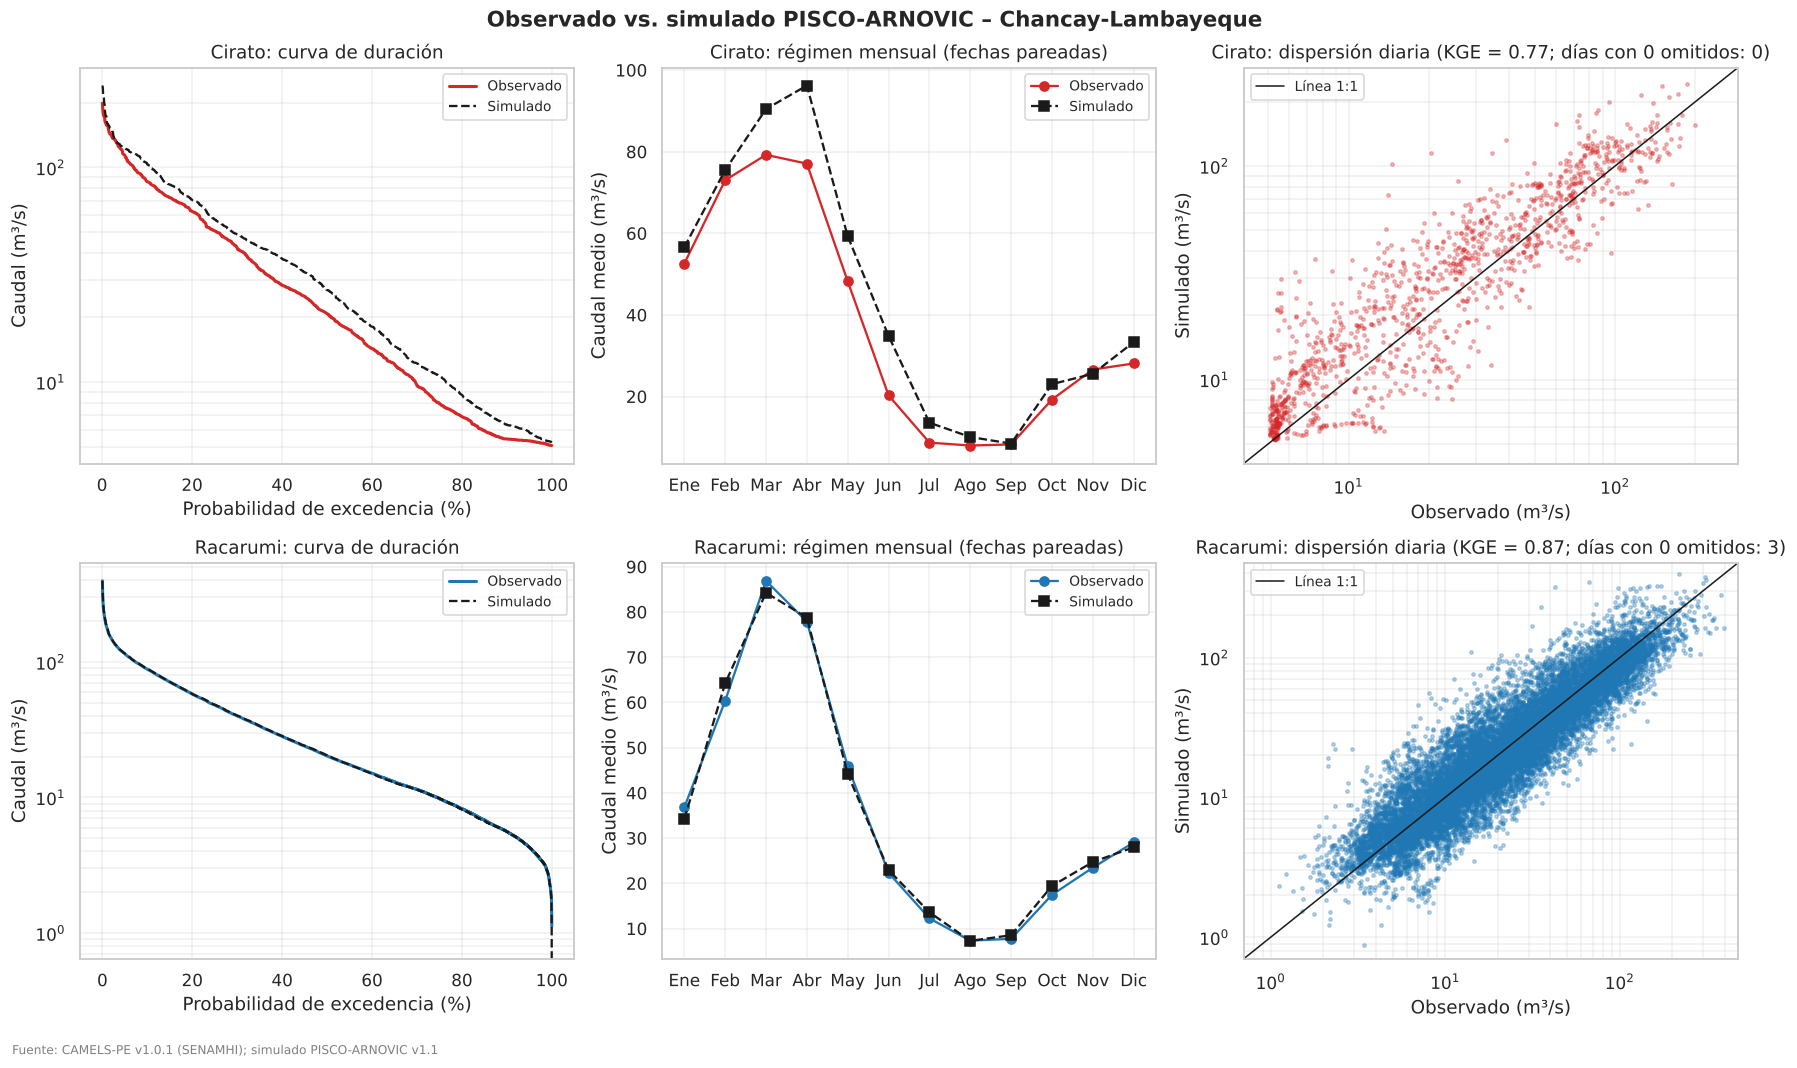

In [24]:
meses_es = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
fig, ejes = plt.subplots(2, 3, figsize=(16, 9.5))
for i, (nombre, p) in enumerate(pareados.items()):
    c = COLORES[nombre]
    po, qo = curva_duracion(p['obs']); ps, qs = curva_duracion(p['sim'])
    ax = ejes[i, 0]
    ax.plot(100 * po, qo, color=c, lw=2, label='Observado'); ax.plot(100 * ps, qs, color='k', lw=1.5, ls='--', label='Simulado')
    ax.set_yscale('log'); ax.set_xlabel('Probabilidad de excedencia (%)'); ax.set_ylabel('Caudal (m³/s)')
    ax.set_title(f'{nombre}: curva de duración'); ax.legend(fontsize=9); ax.grid(True, which='both', alpha=0.3)
    ax = ejes[i, 1]
    reg = p.groupby(p.index.month)[['obs', 'sim']].mean()
    ax.plot(reg.index, reg['obs'], 'o-', color=c, label='Observado'); ax.plot(reg.index, reg['sim'], 's--', color='k', label='Simulado')
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(meses_es); ax.set_ylabel('Caudal medio (m³/s)')
    ax.set_title(f'{nombre}: régimen mensual (fechas pareadas)'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
    ax = ejes[i, 2]
    pos = p[(p['obs'] > 0) & (p['sim'] > 0)]
    ax.scatter(pos['obs'], pos['sim'], s=5, alpha=0.3, color=c)
    lim = [min(pos['obs'].min(), pos['sim'].min()) * 0.8, max(pos['obs'].max(), pos['sim'].max()) * 1.2]
    ax.plot(lim, lim, 'k-', lw=1, label='Línea 1:1')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('Observado (m³/s)'); ax.set_ylabel('Simulado (m³/s)')
    ax.set_title(f"{nombre}: dispersión diaria (KGE = {tabla_metricas.loc[nombre, 'KGE']:.2f}; días con 0 omitidos: {len(p) - len(pos)})")
    ax.legend(fontsize=9, loc='upper left'); ax.grid(True, which='both', alpha=0.3)
fig.suptitle('Observado vs. simulado PISCO-ARNOVIC – Chancay-Lambayeque', fontsize=14, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig04_fdc_regimen_dispersion.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:**
- **Racarumi:** las curvas de duración obs y sim se superponen en todo el rango, que es la firma del mapeo de cuantiles. El régimen mensual coincide (máximo en marzo, ~85–87 m³/s; mínimo en agosto–setiembre, ~7–8 m³/s). La dispersión 1:1 es simétrica alrededor de la diagonal.
- **Cirato:** la curva simulada queda **por encima** de la observada en casi todo su rango, y el régimen mensual simulado de marzo–abril (90–96 m³/s) supera al observado (77–79 m³/s). En la dispersión, los días de caudal bajo observado (5–15 m³/s) quedan sobre la línea 1:1.

### 5.6 Hidrogramas superpuestos y desfase temporal
Observado y simulado del año hidrológico **setiembre 2022 – agosto 2023** (único año hidrológico completo con fechas confiables en ambas estaciones) y correlación cruzada obs–sim para desfases de −5 a +5 días sobre las series depuradas.

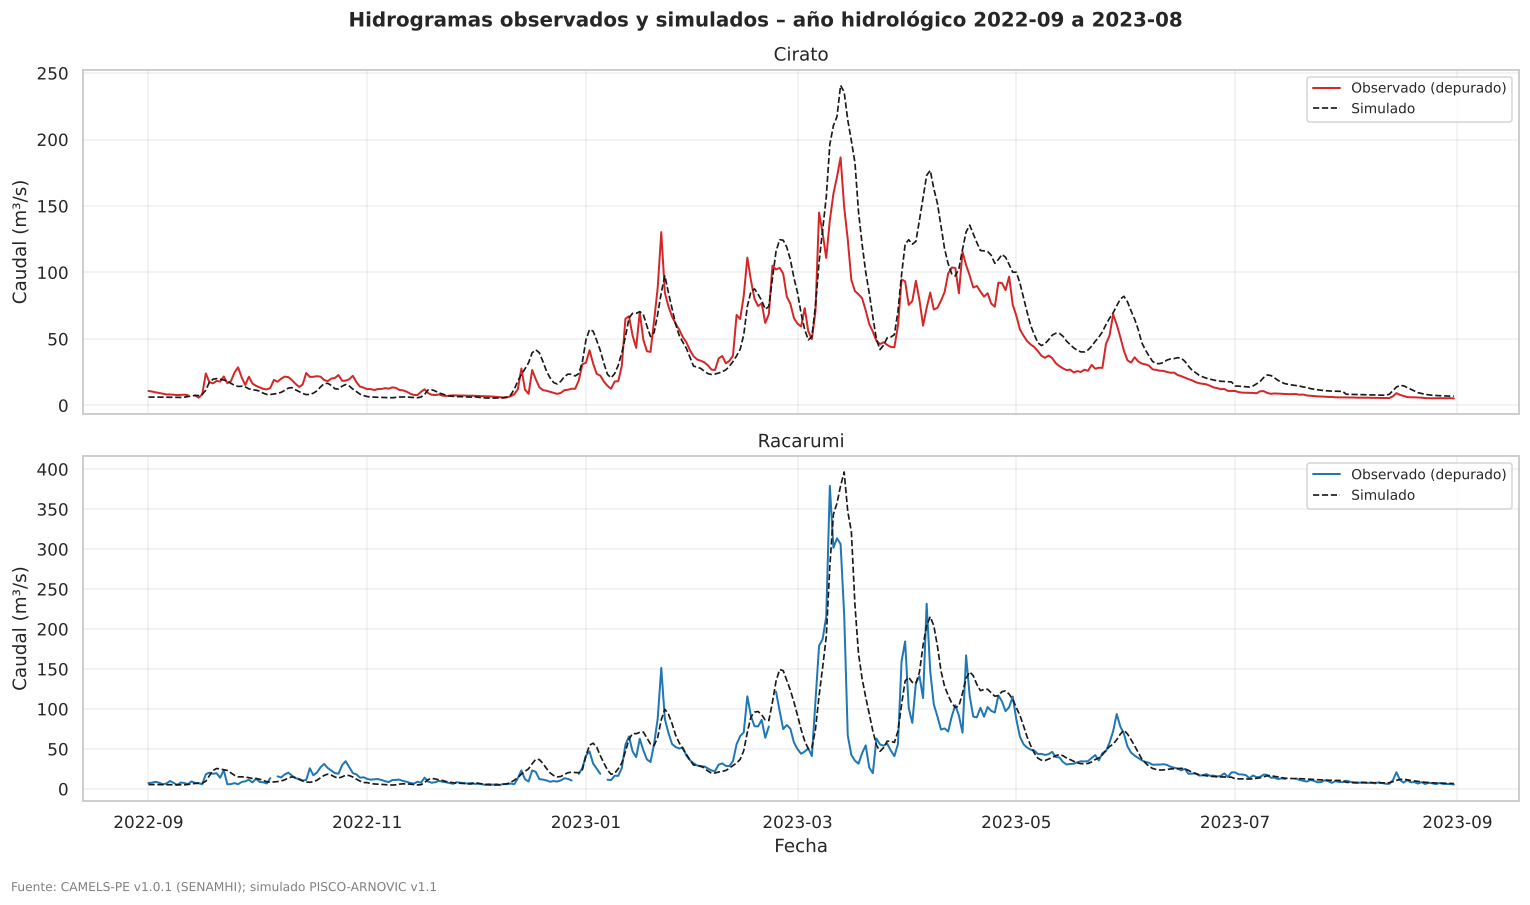

Desfase positivo = el simulado se adelanta (sim en t−lag se alinea con obs en t).


,r (desfase 0),desfase de máx. r (días),r máx.
estación,,,
Cirato,0.895,-1,0.906
Racarumi,0.868,-1,0.889


In [25]:
fig, ejes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, (nombre, df) in zip(ejes, series.items()):
    tramo = df.loc['2022-09-01':'2023-08-31']
    ax.plot(tramo.index, tramo['qobs_dep'], color=COLORES[nombre], lw=1.3, label='Observado (depurado)')
    ax.plot(tramo.index, tramo['qsim'], color='k', lw=1.1, ls='--', label='Simulado')
    ax.set_ylabel('Caudal (m³/s)'); ax.set_title(nombre); ax.legend(loc='upper right', fontsize=9); ax.grid(True, alpha=0.3)
ejes[-1].set_xlabel('Fecha')
fig.suptitle('Hidrogramas observados y simulados – año hidrológico 2022-09 a 2023-08', fontsize=13, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig05_hidrogramas.png', dpi=200, bbox_inches='tight')
plt.show()

filas = []
for nombre, df in series.items():
    corr = {lag: df['qobs_dep'].corr(df['qsim'].shift(lag)) for lag in range(-5, 6)}
    mejor = max(corr, key=corr.get)
    filas.append({'estación': nombre, 'r (desfase 0)': corr[0], 'desfase de máx. r (días)': mejor, 'r máx.': corr[mejor]})
print('Desfase positivo = el simulado se adelanta (sim en t−lag se alinea con obs en t).')
pd.DataFrame(filas).set_index('estación').round(3)

**Interpretación** (setiembre 2022 – agosto 2023):
- **Forma general:** el simulado sigue bien la forma de ambos hidrogramas (subida de enero, crecidas de marzo–abril, recesión hasta agosto).
- **Crecida de marzo de 2023:**
  - Racarumi: observado ~380 m³/s el 10 de marzo frente a un simulado de ~397 m³/s el 14 de marzo.
  - Cirato: observado ~187 m³/s frente a ~240 m³/s simulados.
- **Abril:** el simulado de Cirato sobreestima (~175 frente a ~95 m³/s).
- **Desfase:** el máximo de la correlación cruzada está a **−1 día** en ambas estaciones (r = 0.91 y 0.89), con ganancias de solo 0.01–0.02 sobre el desfase 0. El simulado llega con un día de retraso, un desfase menor. Con las fechas ya corregidas, Cirato queda sincronizada con su simulado.

---
## 6. Correlaciones

### 6.1 Variables hidroclimáticas frente al caudal observado
Matriz de Spearman (Lab3_2) entre caudal observado, simulado, lluvia diaria y acumulada (3 y 7 días), ETP, temperatura media, radiación y presión de vapor, en los días con observado depurado; Pearson sobre log(Q + ε) como complemento.
**Advertencia:** con series autocorrelacionadas los p-valores serían engañosos (Ses6a); la correlación se usa como medida de asociación.

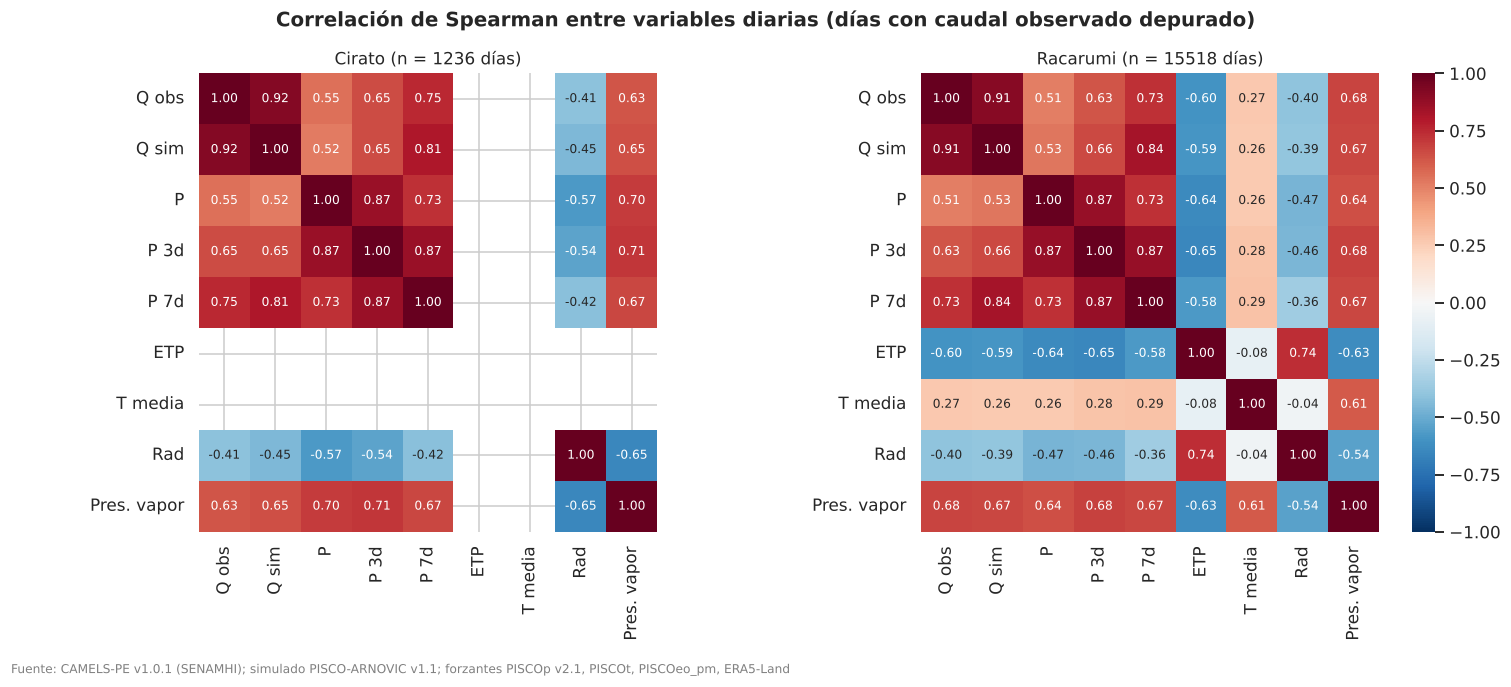

,"Spearman(Qobs, Qsim)","Pearson(log Qobs, log Qsim)","Spearman(Qobs, P 7d)"
estación,,,
Cirato,0.917,0.915,0.752
Racarumi,0.913,0.911,0.733


In [26]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (nombre, df) in zip(ejes, series.items()):
    d = pd.DataFrame({'Q obs': df['qobs_dep'], 'Q sim': df['qsim'], 'P': df['prec'], 'P 3d': df['prec'].rolling(3).sum(),
                      'P 7d': df['prec'].rolling(7).sum(), 'ETP': df['pet'], 'T media': df['tmean'], 'Rad': df['srad'],
                      'Pres. vapor': df['vprp']})
    d = d[d['Q obs'].notna()]
    sns.heatmap(d.corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax,
                cbar=ax is ejes[-1], annot_kws={'size': 8}, square=True)
    ax.set_title(f'{nombre} (n = {len(d)} días)', fontsize=11)
fig.suptitle('Correlación de Spearman entre variables diarias (días con caudal observado depurado)', fontsize=13, fontweight='bold')
nota_fuente(fig, FUENTE + '; forzantes PISCOp v2.1, PISCOt, PISCOeo_pm, ERA5-Land')
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig06_correlaciones.png', dpi=200, bbox_inches='tight')
plt.show()

filas = []
for nombre, df in series.items():
    d = pd.DataFrame({'q': df['qobs_dep'], 's': df['qsim'], 'p7': df['prec'].rolling(7).sum()}).dropna()
    eps = d['q'].mean() / 100
    filas.append({'estación': nombre, 'Spearman(Qobs, Qsim)': stats.spearmanr(d['q'], d['s'])[0],
                  'Pearson(log Qobs, log Qsim)': stats.pearsonr(np.log(d['q'] + eps), np.log(d['s'] + eps))[0],
                  'Spearman(Qobs, P 7d)': stats.spearmanr(d['q'], d['p7'])[0]})
pd.DataFrame(filas).set_index('estación').round(3)

**Interpretación:**
- **Asociación con el caudal observado:** la variable más asociada es el simulado (ρ = 0.92 en Cirato y 0.91 en Racarumi). Le sigue la **lluvia acumulada de 7 días** (ρ = 0.75 y 0.73), por encima de la de 3 días (0.65 y 0.63) y la del día (0.55 y 0.51).
- **Variables estacionales:** la presión de vapor (0.63–0.68) y la radiación (−0.40 a −0.41) se asocian por compartir el ciclo estacional. En Racarumi la ETP es negativa (−0.60) y la temperatura se asocia poco (0.27).
- **Pearson sobre log(Q + ε)** (0.92 y 0.91) coincide con Spearman.
- En Cirato no hay ETP ni temperatura en el periodo confiable.

### 6.2 Tiempo de respuesta lluvia → caudal
Correlación de Spearman entre la lluvia del día *t − k* y el caudal observado del día *t*, *k* = 0–20, sobre **anomalías** (se resta la media de cada mes calendario; Lab5_2), en fechas confiables.
**Por qué:** sin quitar el ciclo estacional la correlación estaría dominada por la estacionalidad compartida. Además, en Cirato sirve de **verificación independiente** de 2.7: con fechas correctas el máximo debe estar a pocos días.

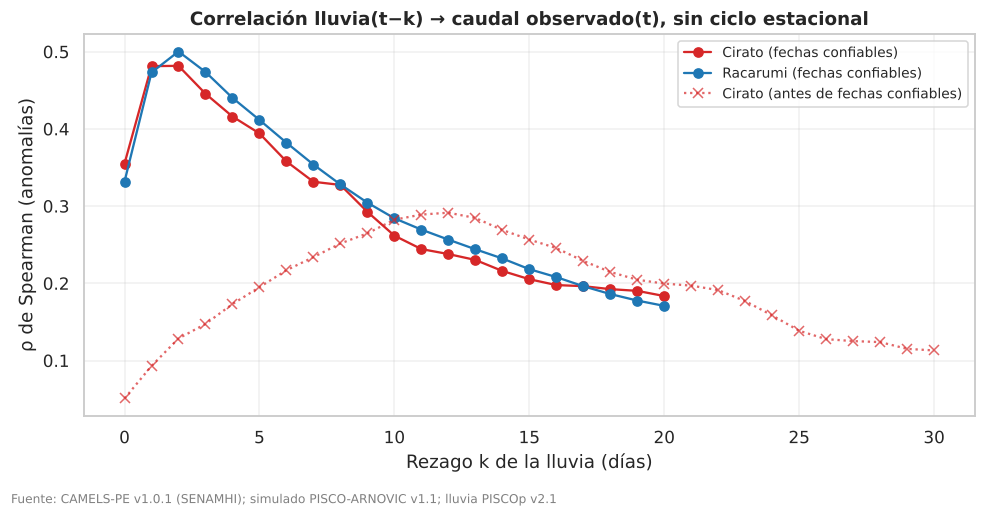

,rezago de máx. ρ (días),ρ máx.
serie,,
Cirato (fechas confiables),2,0.482
Racarumi (fechas confiables),2,0.500
Cirato (antes de fechas confiables),12,0.291


In [27]:
filas = []
fig, ax = plt.subplots(figsize=(9, 4.5))
for nombre, df in series.items():
    lq = log_q(df['qobs_dep'])
    anom_q = lq - lq.groupby(df.index.month).transform('mean')
    anom_p = df['prec'] - df['prec'].groupby(df.index.month).transform('mean')
    corr = [pd.concat([anom_q, anom_p.shift(k)], axis=1).dropna().corr(method='spearman').iloc[0, 1] for k in range(21)]
    ax.plot(range(21), corr, 'o-', color=COLORES[nombre], label=f'{nombre} (fechas confiables)')
    filas.append({'serie': f'{nombre} (fechas confiables)', 'rezago de máx. ρ (días)': int(np.argmax(corr)), 'ρ máx.': max(corr)})
# Cirato con el registro anterior a las fechas confiables (contraste)
df = series['Cirato']
q_ant = df['qobs'].where(df.index < inicio_confiable['Cirato'])
lq = log_q(q_ant)
anom_q = lq - lq.groupby(df.index.month).transform('mean')
anom_p = df['prec'] - df['prec'].groupby(df.index.month).transform('mean')
corr = [pd.concat([anom_q, anom_p.shift(k)], axis=1).dropna().corr(method='spearman').iloc[0, 1] for k in range(31)]
ax.plot(range(31), corr, 'x:', color=COLORES['Cirato'], alpha=0.7, label='Cirato (antes de fechas confiables)')
filas.append({'serie': 'Cirato (antes de fechas confiables)', 'rezago de máx. ρ (días)': int(np.argmax(corr)), 'ρ máx.': max(corr)})
ax.set_xlabel('Rezago k de la lluvia (días)'); ax.set_ylabel('ρ de Spearman (anomalías)')
ax.set_title('Correlación lluvia(t−k) → caudal observado(t), sin ciclo estacional', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
nota_fuente(fig, FUENTE + '; lluvia PISCOp v2.1')
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig07_respuesta_lluvia.png', dpi=200, bbox_inches='tight')
plt.show()
pd.DataFrame(filas).set_index('serie').round(3)

**Interpretación:**
- **Respuesta a la lluvia (sin ciclo estacional):** ambas estaciones alcanzan su máxima correlación con la lluvia de **2 días antes** (ρ = 0.48 en Cirato y 0.50 en Racarumi). La correlación decae gradualmente (0.17–0.18 a 20 días).
- **Verificación independiente de 2.7:** con el registro de Cirato anterior a agosto de 2022, el máximo aparece a **12 días** (ρ = 0.29), con una curva que sube desde 0.05 a k = 0. Este resultado no usa el simulado: confirma con la lluvia que esas fechas están corridas casi dos semanas.
- **Para los modelos:** los rezagos útiles de lluvia están en 1–7 días.

### 6.3 Correlación entre estaciones y con desfase
Correlación de Spearman entre las anomalías de log(Q + ε) de ambas estaciones en el periodo común confiable, y entre Cirato en *t − k* y Racarumi en *t* (*k* = 0–3).
**Por qué:** mide cuánta información comparten y si Cirato anticipa a Racarumi (análisis "aguas arriba" del proyecto).

In [28]:
anom = pd.DataFrame({n: log_q(df['qobs_dep']) - log_q(df['qobs_dep']).groupby(df.index.month).transform('mean')
                     for n, df in series.items()}).loc[desde:]
print(f"Spearman entre estaciones (anomalías, desde {desde.date()}):")
print(anom.dropna().corr(method='spearman').round(3).to_string())
filas = []
for k in range(4):
    d = pd.concat([anom['Racarumi'], anom['Cirato'].shift(k)], axis=1).dropna()
    filas.append({'rezago k (días)': k, 'n': len(d), 'ρ Cirato(t−k) con Racarumi(t)': d.corr(method='spearman').iloc[0, 1]})
pd.DataFrame(filas).set_index('rezago k (días)').round(3)

Spearman entre estaciones (anomalías, desde 2022-08-01):
          Cirato  Racarumi
Cirato     1.000     0.802
Racarumi   0.802     1.000


,n,ρ Cirato(t−k) con Racarumi(t)
rezago k (días),,
0,388,0.802
1,387,0.744
2,386,0.638
3,385,0.561


**Interpretación** (desde 2022-08-01; ~388 días): las anomalías de ambas estaciones están bien correlacionadas (ρ = **0.80**). Sin embargo, la correlación de Cirato(t − k) con Racarumi(t) es **máxima a k = 0** y cae rápido con el rezago (0.74, 0.64 y 0.56 a 1–3 días). A escala diaria, **Cirato no anticipa a Racarumi**: el tránsito entre ambas estaciones dura menos de un día. La muestra es corta (13 meses).

### 6.4 Atributos de cuenca y desempeño del simulado
Atributos principales y métricas del simulado.
**Por qué no se calcula una correlación:** con **n = 2** cuencas anidadas no existe ningún estadístico de asociación con sentido; la tabla es solo descriptiva.

In [29]:
tabla_atr_des = pd.concat([
    atrib.set_index('estacion')[['area', 'elev_mean', 'p_mean', 'aridity', 'agricul_perc', 'forest_perc',
                                 'baseflow_index', 'runoff_ratio', 'reservoir_n']],
    tabla_metricas[['KGE', 'NSE', 'PBIAS (%)', 'NSE-log', 'BE (vs clim. mensual)']]], axis=1)
tabla_atr_des.round(3)

,area,elev_mean,p_mean,aridity,agricul_perc,forest_perc,baseflow_index,runoff_ratio,reservoir_n,KGE,NSE,PBIAS (%),NSE-log,BE (vs clim. mensual)
Cirato,1611.901,2630.597,3.502,0.910,68.388,6.128,0.550,0.548,3,0.773,0.728,17.054,0.799,0.455
Racarumi,2363.302,2348.974,3.007,1.061,52.703,20.589,0.522,0.428,6,0.867,0.733,0.506,0.821,0.524


**Interpretación:** Cirato es más alta (2 631 m de elevación media), más lluviosa (3.50 mm/d), más agrícola (68 %) y tiene mayor coeficiente de escorrentía (0.55 frente a 0.43). Racarumi tiene más presas registradas (6 frente a 3). El mejor KGE de Racarumi (0.87 frente a 0.77) se explica por la calidad y la longitud de su registro, y por el ajuste por cuantiles a ese registro, no por la fisiografía. Con n = 2 no se infiere ninguna relación.

---
## 7. Validación de hipótesis del diagnóstico

Para cada hipótesis: enunciado → variables → prueba (con supuestos) → resultado (estadístico, p-valor o IC, tamaño de efecto) → conclusión y limitaciones. α = 0.05. En Cirato todas las pruebas usan **solo el periodo con fechas confiables**.

**Supuesto transversal — independencia:** se cuantifica abajo la autocorrelación de rezago 1 (Lab5_1); ninguna prueba trata días individuales como independientes.

In [30]:
filas = []
for nombre, p in pareados.items():
    filas.append({'estación': nombre, 'n días': len(p), 'r1 obs': p['obs'].autocorr(1), 'r1 sim': p['sim'].autocorr(1),
                  'r1 error (sim−obs)': (p['sim'] - p['obs']).autocorr(1),
                  'p ADF obs (diario)': adfuller(p['obs'].values, maxlag=30)[1]})
pd.DataFrame(filas).set_index('estación').round(4)

,n días,r1 obs,r1 sim,r1 error (sim−obs),p ADF obs (diario)
estación,,,,,
Cirato,1236,0.9608,0.9840,0.8508,0.0397
Racarumi,15518,0.9381,0.9855,0.7865,0.0000


**Interpretación:**
- **Persistencia del error:** la autocorrelación de rezago 1 es 0.94–0.98 en obs y sim y **0.85 (Cirato) y 0.79 (Racarumi) en el error**. Con errores tan persistentes, los 1 236 días de Cirato equivalen a muy pocos datos independientes, lo que explica sus IC más anchos en 5.1.
- **Estacionariedad:** la prueba ADF (p ≤ 0.04) indica series estacionarias alrededor de su ciclo, lo que valida el bootstrap por bloques.

### 7.1 H1 — Sustitución
> **H1.** "En cada estación, el caudal simulado (i) supera al benchmark climatológico mensual a escala diaria (BE > 0) y (ii) alcanza desempeño mensual satisfactorio (NSE > 0.50 y |PBIAS| ≤ 25 %)."

- **Prueba:** se exige que el límite inferior del IC 95 % (bootstrap de bloques mensuales) supere el umbral: BE_inf > 0 y NSE mensual_inf > 0.50; |PBIAS| se evalúa con su IC.

In [31]:
filas = []
for nombre, p in pareados.items():
    p = p.copy()
    p['bench'] = climatologia_mensual(p)
    be = bootstrap_bloques_mensuales(p, lambda d: eficiencia_benchmark(d['obs'], d['sim'], d['bench']))
    pm = mensuales[nombre]
    nse_m = bootstrap_bloques_mensuales(pm, lambda d: nse(d['obs'], d['sim']))
    pb_m = bootstrap_bloques_mensuales(pm, lambda d: pbias(d['obs'], d['sim']))
    cumple = (np.percentile(be, 2.5) > 0) and (np.percentile(nse_m, 2.5) > NSE_MENSUAL_MIN) and \
             (max(abs(np.percentile(pb_m, 2.5)), abs(np.percentile(pb_m, 97.5))) <= PBIAS_MAX)
    filas.append({'estación': nombre, 'BE diario': eficiencia_benchmark(p['obs'], p['sim'], p['bench']),
                  'BE IC95': f"[{np.percentile(be, 2.5):.2f}, {np.percentile(be, 97.5):.2f}]",
                  'NSE mensual': nse(pm['obs'], pm['sim']),
                  'NSE mensual IC95': f"[{np.percentile(nse_m, 2.5):.2f}, {np.percentile(nse_m, 97.5):.2f}]",
                  'PBIAS mensual (%)': pbias(pm['obs'], pm['sim']),
                  'PBIAS IC95': f"[{np.percentile(pb_m, 2.5):.1f}, {np.percentile(pb_m, 97.5):.1f}]",
                  'n meses': len(pm), 'H1 se cumple': cumple})
tabla_h1 = pd.DataFrame(filas).set_index('estación').round(3)
tabla_h1

,BE diario,BE IC95,NSE mensual,NSE mensual IC95,PBIAS mensual (%),PBIAS IC95,n meses,H1 se cumple
estación,,,,,,,,
Cirato,0.455,"[0.08, 0.66]",0.851,"[0.70, 0.93]",16.854,"[8.2, 27.3]",40,False
Racarumi,0.524,"[0.42, 0.61]",0.848,"[0.79, 0.90]",0.632,"[-2.5, 3.8]",510,True


**Resultado y conclusión H1:**
- **Racarumi: se cumple.**
  - BE = 0.52 (IC 0.42–0.61, completamente > 0).
  - NSE mensual = 0.85 (IC 0.79–0.90).
  - PBIAS mensual +0.6 % (IC −2.5 a +3.8 %).
- **Cirato: no se cumple.**
  - BE = 0.45 (IC 0.08–0.66) y NSE mensual = 0.85 (IC 0.70–0.93) sí cumplen.
  - Falla el sesgo: PBIAS mensual **+16.9 %**, con IC **+8.2 a +27.3 %**, que supera el ±25 %.

**H1 se rechaza para la cuenca**, porque la regla exige las dos estaciones.

**Limitación:** el cumplimiento de Racarumi incluye 1981–2020, dentro de la ventana de calibración y del ajuste por cuantiles. En el periodo reciente común con Cirato su BE cae a 0.02 (5.2).

### 7.2 H2 — Subestimación de crecidas
> **H2.** "El simulado subestima los picos de crecida observados (mediana del error relativo en picos independientes < 0)."

- **Variables:** picos del observado sobre su P90, desagrupados con θ = 5 + ln(A[mi²]) días (USWRC, en Lang et al., 1999); para cada pico, el máximo simulado en ±2 días.
- **Prueba:** Wilcoxon de rangos con signo unilateral (extensión pareada de Mann-Whitney, Lab3_2); Shapiro-Wilk para decidir entre Wilcoxon y t pareada; tamaño de efecto: correlación biserial de rangos.
- **Control de sesgo de selección:** se repite eligiendo los picos sobre el simulado; se reporta FHV.

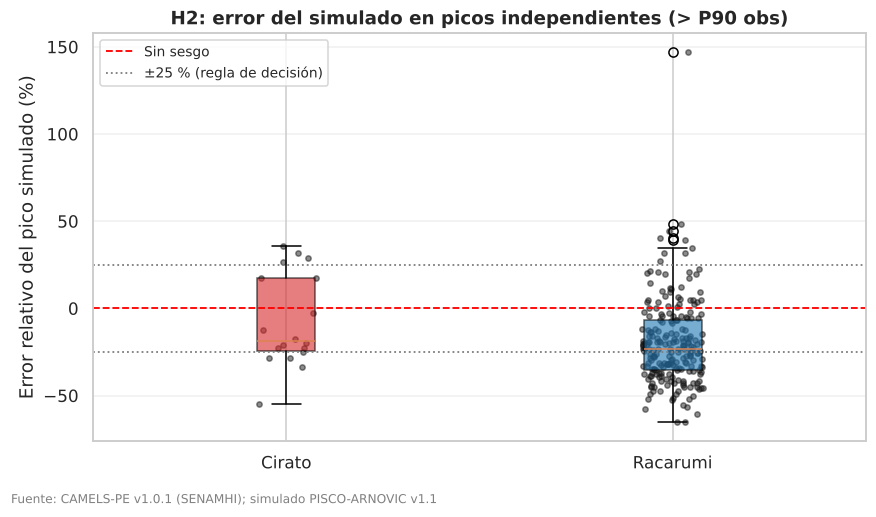

,θ (días),n picos,mediana error rel. (%),P25–P75 (%),picos subestimados (%),Shapiro p,Wilcoxon W,p (unilateral),r biserial,FHV (%),picos elegidos en sim: mediana (obs−sim)/sim (%)
estación,,,,,,,,,,,
Cirato,12,18,-18.8625,-24.6 a 17.3,66.6667,0.0661,64.0,0.1846,-0.2515,10.9464,-16.9
Racarumi,12,221,-23.3707,-35.4 a -6.9,81.9005,0.0000,2717.0,0.0000,-0.7785,1.1373,13.7


In [32]:
def picos_independientes(q, umbral, separacion):
    """Picos sobre 'umbral' separados al menos 'separacion' días (se conserva el mayor de cada grupo)."""
    picos = []
    for fecha, valor in q[q > umbral].dropna().sort_values(ascending=False).items():
        if all(abs((fecha - f).days) >= separacion for f, _ in picos):
            picos.append((fecha, valor))
    return pd.Series(dict(picos)).sort_index()

filas, errores_picos = [], {}
for nombre, df in series.items():
    q = df['qobs_dep']
    theta = int(np.ceil(5 + np.log(area[nombre] / 2.58999)))
    picos = picos_independientes(q, q.quantile(0.90), theta)
    sim_max = [df['qsim'].loc[f - pd.Timedelta(days=2): f + pd.Timedelta(days=2)].max() for f in picos.index]
    err = pd.Series((np.array(sim_max) - picos.values) / picos.values, index=picos.index)
    errores_picos[nombre] = err
    w = stats.wilcoxon(err, alternative='less')
    rangos = stats.rankdata(np.abs(err))
    w_mas, w_menos = rangos[err > 0].sum(), rangos[err < 0].sum()
    filas.append({'estación': nombre, 'θ (días)': theta, 'n picos': len(err), 'mediana error rel. (%)': 100 * err.median(),
                  'P25–P75 (%)': f"{100 * err.quantile(.25):.1f} a {100 * err.quantile(.75):.1f}",
                  'picos subestimados (%)': 100 * (err < 0).mean(), 'Shapiro p': stats.shapiro(err).pvalue,
                  'Wilcoxon W': w.statistic, 'p (unilateral)': w.pvalue, 'r biserial': (w_mas - w_menos) / (w_mas + w_menos),
                  'FHV (%)': tabla_metricas.loc[nombre, 'FHV (%)']})
tabla_h2 = pd.DataFrame(filas).set_index('estación').round(4)

simetria = {}
for nombre, df in series.items():
    s_sim = df['qsim'].where(df['qobs_dep'].notna())
    picos_s = picos_independientes(s_sim, s_sim.quantile(0.90), tabla_h2.loc[nombre, 'θ (días)'])
    obs_max = [df['qobs_dep'].loc[f - pd.Timedelta(days=2): f + pd.Timedelta(days=2)].max() for f in picos_s.index]
    simetria[nombre] = 100 * np.median((np.array(obs_max) - picos_s.values) / picos_s.values)
tabla_h2['picos elegidos en sim: mediana (obs−sim)/sim (%)'] = pd.Series(simetria).round(1)

fig, ax = plt.subplots(figsize=(8, 4.5))
nombres = list(ESTACIONES.values())
bp = ax.boxplot([100 * errores_picos[n] for n in nombres], tick_labels=nombres, patch_artist=True)
for caja, n in zip(bp['boxes'], nombres):
    caja.set_facecolor(COLORES[n]); caja.set_alpha(0.6)
for i, n in enumerate(nombres, start=1):
    ax.scatter(np.full(len(errores_picos[n]), i) + rng.uniform(-0.08, 0.08, len(errores_picos[n])),
               100 * errores_picos[n], s=12, color='k', alpha=0.5)
ax.axhline(0, color='red', ls='--', lw=1.2, label='Sin sesgo')
ax.axhline(-SESGO_PICOS_MAX, color='gray', ls=':', lw=1.2, label=f'±{SESGO_PICOS_MAX:.0f} % (regla de decisión)')
ax.axhline(SESGO_PICOS_MAX, color='gray', ls=':', lw=1.2)
ax.set_ylabel('Error relativo del pico simulado (%)')
ax.set_title('H2: error del simulado en picos independientes (> P90 obs)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, axis='y', alpha=0.3)
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig08_h2_picos.png', dpi=200, bbox_inches='tight')
plt.show()
tabla_h2

**Resultado y conclusión H2:**

**Racarumi (221 picos): se acepta H2.** Hay subestimación significativa:
- mediana −23.4 %; 82 % de los picos subestimados;
- Wilcoxon p < 0.0001; efecto grande (r biserial −0.78); Shapiro rechaza la normalidad, por eso Wilcoxon.

El control de selección invierte el signo: con picos elegidos en el simulado, el observado queda **+13.7 %** por encima, y FHV es +1.1 %. Buena parte de la "subestimación" se debe a que el simulado no coloca sus crecidas en los mismos días.

**Cirato (18 picos): no se acepta H2.** La mediana es −18.9 %, pero no es significativa (Wilcoxon p = 0.18; r biserial −0.25), con pocos eventos.

Ambas estaciones cumplen el criterio |mediana| ≤ 25 % de la regla de decisión.

### 7.3 H3 — Diferencia de desempeño entre épocas
> **H3.** "El KGE del simulado difiere entre la época húmeda y la seca."

- **Prueba:** ΔKGE = KGE_húmeda − KGE_seca con IC 95 % por bootstrap estratificado de bloques mensuales; bilateral.

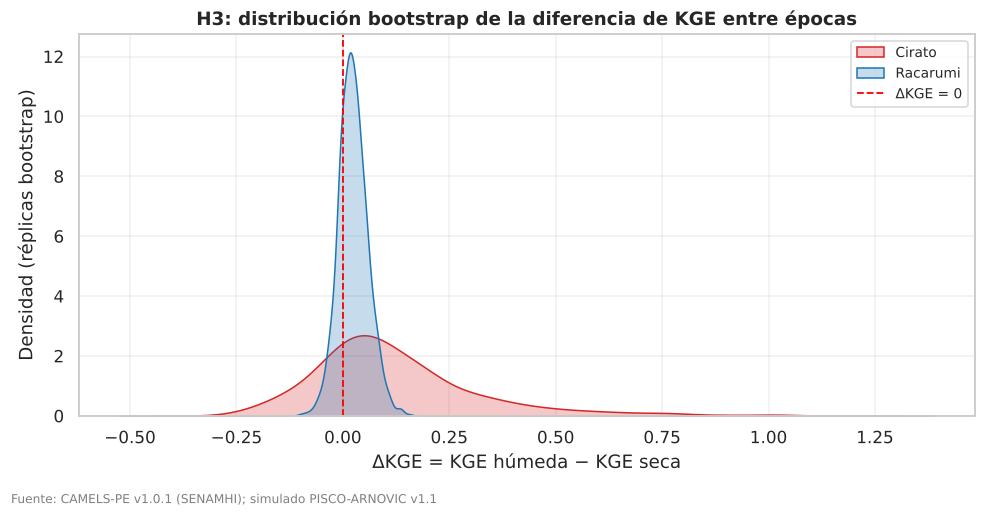

,KGE húmeda,KGE seca,ΔKGE,IC95 ΔKGE,p bootstrap (bilateral),se rechaza H0
estación,,,,,,
Cirato,0.754,0.675,0.079,"[-0.17, 0.67]",0.506,False
Racarumi,0.810,0.787,0.023,"[-0.04, 0.09]",0.498,False


In [33]:
filas, deltas = [], {}
for nombre, p in pareados.items():
    hum = p[p.index.month.isin(meses_humedos[nombre])]
    sec = p[~p.index.month.isin(meses_humedos[nombre])]
    b_h = bootstrap_bloques_mensuales(hum, lambda d: kge(d['obs'], d['sim'])[0], semilla=SEMILLA)
    b_s = bootstrap_bloques_mensuales(sec, lambda d: kge(d['obs'], d['sim'])[0], semilla=SEMILLA + 1)
    delta = b_h - b_s
    deltas[nombre] = delta
    ic = np.percentile(delta, [2.5, 97.5])
    k_h, k_s = kge(hum['obs'], hum['sim'])[0], kge(sec['obs'], sec['sim'])[0]
    filas.append({'estación': nombre, 'KGE húmeda': k_h, 'KGE seca': k_s, 'ΔKGE': k_h - k_s,
                  'IC95 ΔKGE': f"[{ic[0]:.2f}, {ic[1]:.2f}]", 'p bootstrap (bilateral)': 2 * min((delta <= 0).mean(), (delta >= 0).mean()),
                  'se rechaza H0': not (ic[0] <= 0 <= ic[1])})
tabla_h3 = pd.DataFrame(filas).set_index('estación').round(3)

fig, ax = plt.subplots(figsize=(9, 4.5))
for n, d in deltas.items():
    sns.kdeplot(d, ax=ax, color=COLORES[n], fill=True, alpha=0.25, label=n)
ax.axvline(0, color='red', ls='--', lw=1.2, label='ΔKGE = 0')
ax.set_xlabel('ΔKGE = KGE húmeda − KGE seca'); ax.set_ylabel('Densidad (réplicas bootstrap)')
ax.set_title('H3: distribución bootstrap de la diferencia de KGE entre épocas', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig09_h3_epocas.png', dpi=200, bbox_inches='tight')
plt.show()
tabla_h3

**Resultado y conclusión H3:** **no se rechaza H0 en ninguna estación.**
- Cirato: ΔKGE = +0.08 (IC −0.17 a 0.67; p = 0.51).
- Racarumi: ΔKGE = +0.02 (IC −0.04 a 0.09; p = 0.50).

En Racarumi, con 42 años, el IC es estrecho y centrado cerca de 0: el desempeño del simulado es **similar en lluvias y en estiaje**. En Cirato el IC es muy amplio por la muestra corta.

### 7.4 H4 — Dinámica de corto plazo
> **H4.** "El simulado reproduce la variabilidad día a día del observado." H0: RB_sim = RB_obs.

- **Prueba:** razón RB_sim/RB_obs con IC 95 % por bootstrap de bloques mensuales (Σ|ΔQ| y ΣQ dentro de cada mes). Complemento: autocorrelación de rezago 1 y tiempo de decorrelación de las anomalías de log(Q + ε).

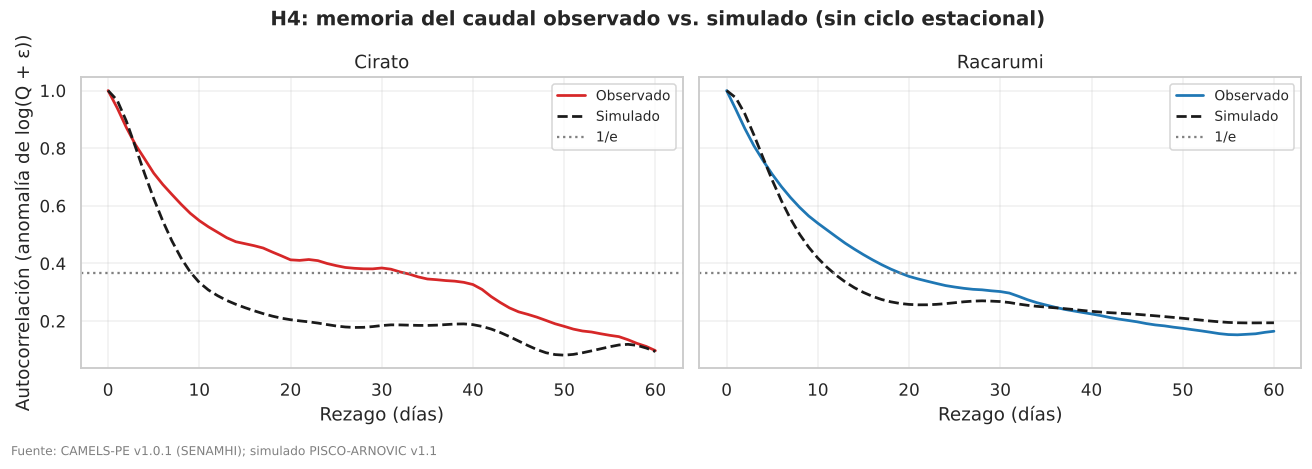

,RB obs,RB sim,razón RB sim/obs,IC95 razón,se rechaza H0,r1 obs,r1 sim,T_dec anomalía obs (d),T_dec anomalía sim (d)
estación,,,,,,,,,
Cirato,0.146,0.104,0.717,"[0.631, 0.807]",True,0.961,0.984,33,10
Racarumi,0.178,0.103,0.580,"[0.550, 0.599]",True,0.938,0.985,19,12


In [34]:
def sumas_rb_mensuales(p):
    """Para cada mes: Σ|ΔQ| y ΣQ de obs y sim con pares de días consecutivos válidos en ambas series."""
    filas = []
    for _, g in p.groupby([p.index.year, p.index.month]):
        g = g.asfreq('D')
        dq_o, dq_s = g['obs'].diff().abs(), g['sim'].diff().abs()
        val = dq_o.notna() & dq_s.notna()
        filas.append([dq_o[val].sum(), dq_s[val].sum(), g['obs'][val].sum(), g['sim'][val].sum()])
    return np.array(filas)

def tiempo_decorrelacion(s, max_lag=60):
    """Rezago (días) en que la autocorrelación de s cae bajo 1/e."""
    for k in range(1, max_lag + 1):
        if s.autocorr(k) < np.exp(-1):
            return k
    return np.nan

def anomalia_log(s, eps):
    """Anomalía de log(Q + ε) respecto a la media de cada mes calendario."""
    l = np.log(s + eps)
    return l - l.groupby(l.index.month).transform('mean')

filas = []
for nombre, p in pareados.items():
    pd_d = p.asfreq('D')
    eps = p['obs'].mean() / 100
    rb_o = richards_baker(pd_d['obs'].where(pd_d['sim'].notna()))
    rb_s = richards_baker(pd_d['sim'].where(pd_d['obs'].notna()))
    sumas = sumas_rb_mensuales(p)
    gen = np.random.default_rng(SEMILLA)
    boot = np.empty(N_BOOT)
    for b in range(N_BOOT):
        m = sumas[gen.integers(0, len(sumas), len(sumas))].sum(axis=0)
        boot[b] = (m[1] / m[3]) / (m[0] / m[2])
    ic = np.percentile(boot, [2.5, 97.5])
    filas.append({'estación': nombre, 'RB obs': rb_o, 'RB sim': rb_s, 'razón RB sim/obs': rb_s / rb_o,
                  'IC95 razón': f"[{ic[0]:.3f}, {ic[1]:.3f}]", 'se rechaza H0': not (ic[0] <= 1 <= ic[1]),
                  'r1 obs': p['obs'].autocorr(1), 'r1 sim': p['sim'].autocorr(1),
                  'T_dec anomalía obs (d)': tiempo_decorrelacion(anomalia_log(pd_d['obs'], eps)),
                  'T_dec anomalía sim (d)': tiempo_decorrelacion(anomalia_log(pd_d['sim'], eps))})
tabla_h4 = pd.DataFrame(filas).set_index('estación').round(3)
for col in ['T_dec anomalía obs (d)', 'T_dec anomalía sim (d)']:      # NaN = no cae bajo 1/e en 60 días
    tabla_h4[col] = tabla_h4[col].apply(lambda v: '> 60' if pd.isna(v) else str(int(v)))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (nombre, p) in zip(ejes, pareados.items()):
    pd_d = p.asfreq('D')
    eps = p['obs'].mean() / 100
    for col, estilo, etiqueta in [('obs', '-', 'Observado'), ('sim', '--', 'Simulado')]:
        a = anomalia_log(pd_d[col], eps)
        ax.plot(range(61), [a.autocorr(k) for k in range(61)], estilo,
                color=COLORES[nombre] if col == 'obs' else 'k', lw=1.8, label=etiqueta)
    ax.axhline(np.exp(-1), color='gray', ls=':', label='1/e')
    ax.set_xlabel('Rezago (días)'); ax.set_title(nombre); ax.grid(True, alpha=0.3); ax.legend(fontsize=9)
ejes[0].set_ylabel('Autocorrelación (anomalía de log(Q + ε))')
fig.suptitle('H4: memoria del caudal observado vs. simulado (sin ciclo estacional)', fontsize=13, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig10_h4_memoria.png', dpi=200, bbox_inches='tight')
plt.show()
tabla_h4

**Resultado y conclusión H4:** **se rechaza H0 en ambas estaciones.** RB_sim/RB_obs es **0.72** (IC 0.63–0.81) en Cirato y **0.58** (IC 0.55–0.60) en Racarumi: el simulado es un 28–42 % más suave día a día que el río.

**Memoria del caudal:** el observado conserva sus anomalías más tiempo que el simulado. El tiempo de decorrelación es **33 días** (obs) frente a 10 (sim) en Cirato, y **19 días** frente a 12 en Racarumi.

**Para HP1:** un modelo entrenado con el simulado vería un río con variaciones diarias más suaves pero con anomalías menos persistentes que las reales. Ambas diferencias distorsionarían el horizonte útil. Para medir cuánto aviso da el río, la variable objetivo debe ser el **observado**.

### 7.5 Decisión: ¿se puede trabajar solo con el caudal simulado?
Se aplica la regla fijada en 0.4.

In [35]:
decision = pd.DataFrame({
    'H1 cumple': tabla_h1['H1 se cumple'],
    '|mediana error picos| ≤ 25 %': tabla_h2['mediana error rel. (%)'].abs() <= SESGO_PICOS_MAX,
    'H4: IC incluye igualdad': ~tabla_h4['se rechaza H0'],
})
decision['simulado sustituye al observado'] = decision.all(axis=1)
decision.to_csv(RUTA_TAB / 'tabla_decision_simulado.csv')
decision

,H1 cumple,|mediana error picos| ≤ 25 %,H4: IC incluye igualdad,simulado sustituye al observado
estación,,,,
Cirato,False,True,False,False
Racarumi,True,True,False,False


**Decisión (regla fijada en 0.4): el caudal simulado NO puede sustituir al observado en ninguna de las dos estaciones.**
- **Cirato:** falla H1 (sesgo de +17 %) y H4.
- **Racarumi:** cumple H1 y el criterio de picos, pero falla H4: es 42 % más suave que el río.

**Uso recomendado del simulado:**
- **Sí:** como predictor o contexto estacional, para el régimen mensual, y en Racarumi como referencia razonable en 1981–2020.
- **No:**
  - como variable objetivo;
  - para magnitudes de crecida (asigna el máximo observado a 2023);
  - para la dinámica diaria (es más suave que el río).

---
## 8. Visualización y mapas

### 8.1 Distribuciones
Histogramas de log₁₀(Q) (Lab4_2, `sns.histplot` con KDE; los días con Q = 0 se cuentan aparte) y diagramas de caja por mes en escala log (Ses2, Lab4_2), en fechas confiables.

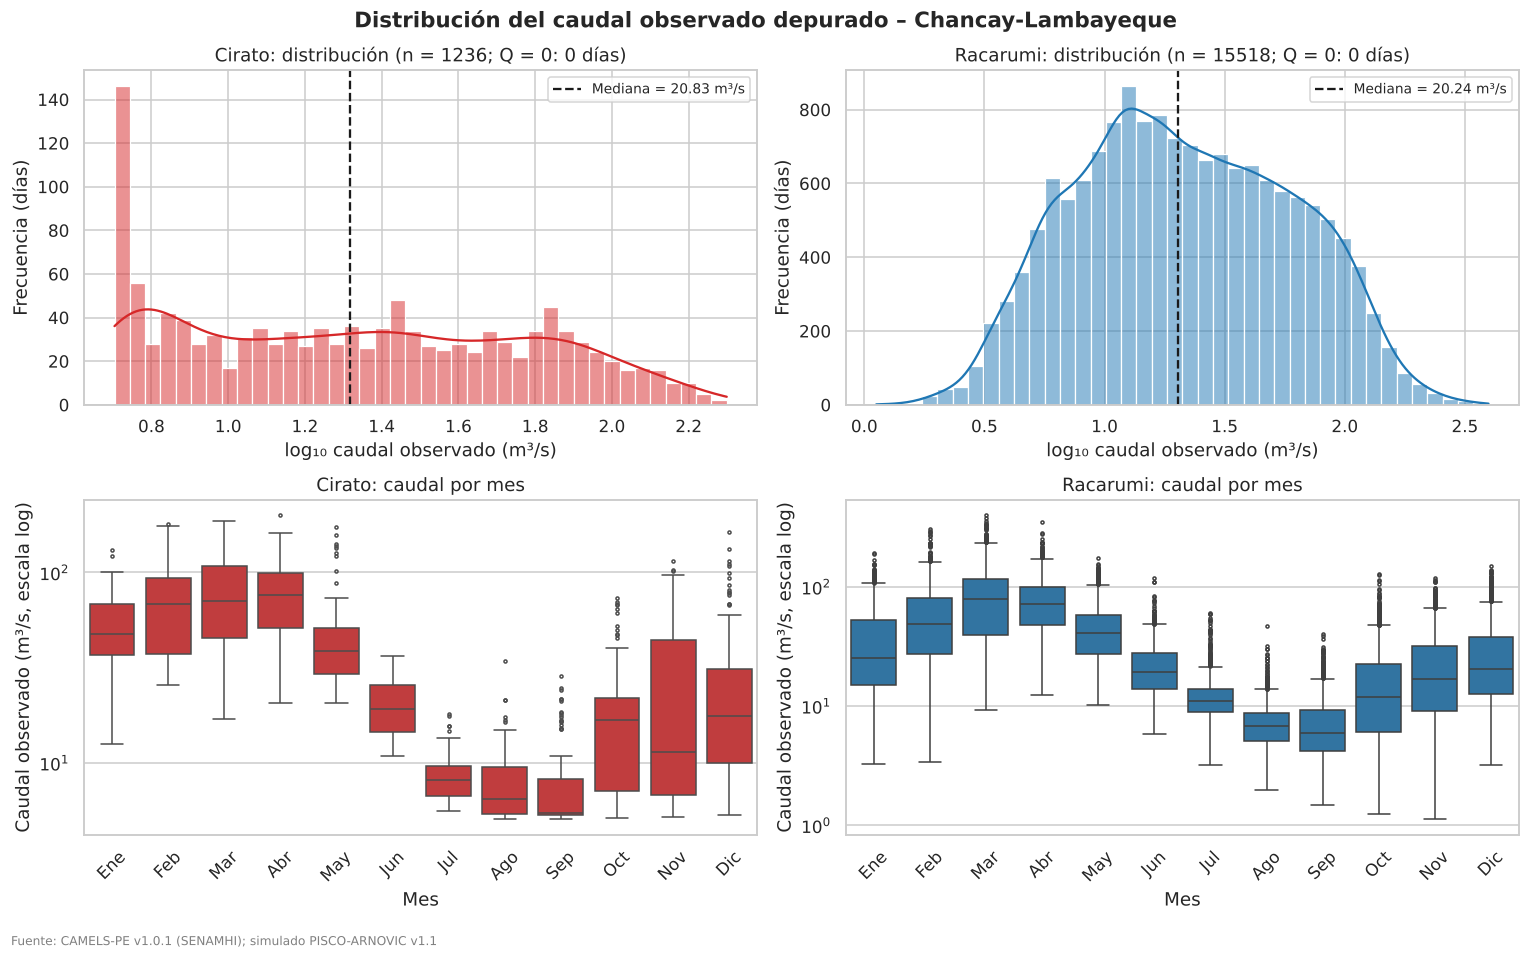

In [36]:
fig, ejes = plt.subplots(2, 2, figsize=(14, 8.5))
for j, (nombre, df) in enumerate(series.items()):
    q = df['qobs_dep'].dropna()
    qpos = q[q > 0]
    ax = ejes[0, j]
    sns.histplot(np.log10(qpos), bins=40, kde=True, color=COLORES[nombre], ax=ax)
    ax.axvline(np.log10(q.median()), color='k', ls='--', label=f'Mediana = {q.median():.2f} m³/s')
    ax.set_xlabel('log₁₀ caudal observado (m³/s)'); ax.set_ylabel('Frecuencia (días)')
    ax.set_title(f'{nombre}: distribución (n = {len(q)}; Q = 0: {int((q == 0).sum())} días)'); ax.legend(fontsize=9)
    ax = ejes[1, j]
    d = pd.DataFrame({'q': qpos, 'mes': qpos.index.month})
    sns.boxplot(data=d, x='mes', y='q', color=COLORES[nombre], ax=ax, fliersize=2)
    ax.set_yscale('log'); ax.set_xticks(range(12)); ax.set_xticklabels(meses_es, rotation=45)
    ax.set_xlabel('Mes'); ax.set_ylabel('Caudal observado (m³/s, escala log)'); ax.set_title(f'{nombre}: caudal por mes')
fig.suptitle('Distribución del caudal observado depurado – Chancay-Lambayeque', fontsize=14, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig11_distribuciones.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:**
- **Racarumi:** en escala log tiene una distribución unimodal y algo asimétrica (de ~1 a ~400 m³/s), con mediana de **20.24 m³/s**.
- **Cirato (periodo confiable):** la distribución es casi plana entre 6 y 150 m³/s (mediana **20.83 m³/s**), con una **acumulación de ~146 días en el extremo inferior (~5 m³/s)**, cerca del mínimo absoluto (5.056 m³/s). Puede ser un límite inferior de lectura o un caudal de estiaje regulado aguas arriba; con estos datos no se puede distinguir. En los caudales bajos de Cirato hay que leer con cautela el sesgo del simulado (5.4).
- **Por mes:** las cajas muestran el ciclo estacional, con máximos en marzo–abril y mínimos en agosto–setiembre. Los puntos atípicos de los meses de lluvia son **crecidas reales**: no se usan cajas para eliminar datos.

### 8.2 Series de tiempo completas y medias móviles
Serie diaria observada (depurada) y simulada 1981–2025 con media móvil de 30 días (Lab5_1, `rolling`); en Cirato se sombrea el periodo **excluido** por error de fechas y se muestra en gris claro el observado del archivo.

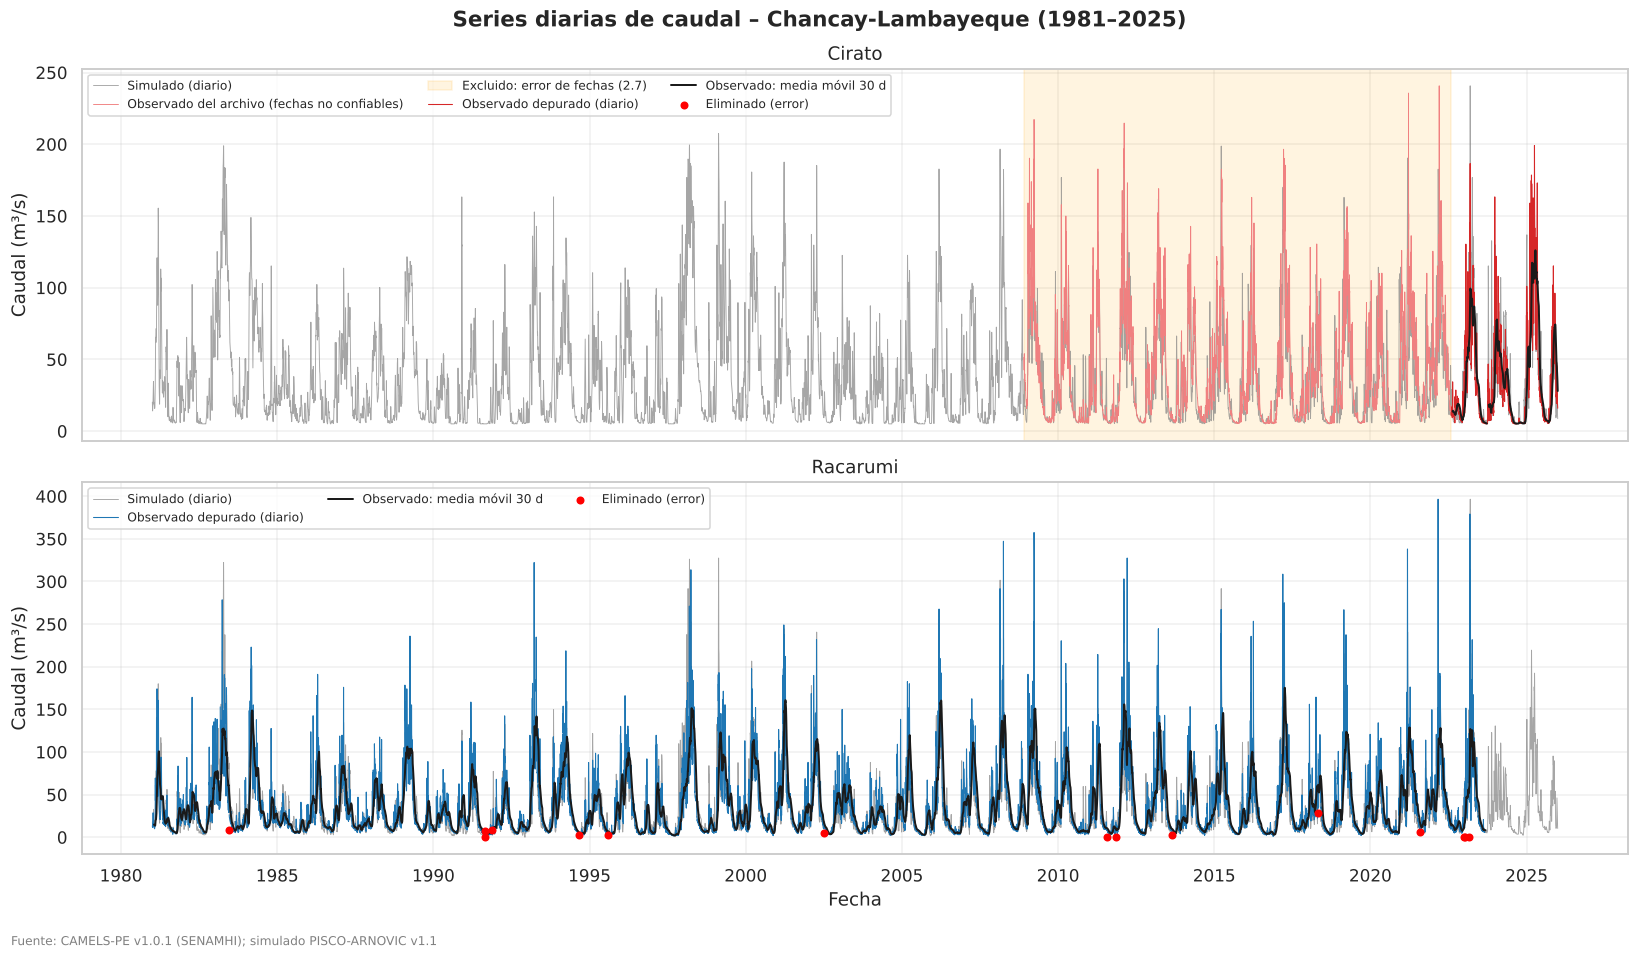

In [37]:
fig, ejes = plt.subplots(2, 1, figsize=(15, 8.5), sharex=True)
for ax, (nombre, df) in zip(ejes, series.items()):
    ax.plot(df.index, df['qsim'], color='gray', lw=0.6, alpha=0.7, label='Simulado (diario)')
    if nombre == 'Cirato':
        ax.plot(df.index, df['qobs'].where(df.index < inicio_confiable[nombre]), color='lightcoral', lw=0.6,
                label='Observado del archivo (fechas no confiables)')
        ax.axvspan(df['qobs'].first_valid_index(), inicio_confiable[nombre], color='orange', alpha=0.12,
                   label='Excluido: error de fechas (2.7)')
    ax.plot(df.index, df['qobs_dep'], color=COLORES[nombre], lw=0.7, label='Observado depurado (diario)')
    ax.plot(df.index, df['qobs_dep'].rolling(30, min_periods=20).mean(), color='k', lw=1.3, label='Observado: media móvil 30 d')
    err = df.index[banderas[nombre].reindex(df.index).fillna(False).values]
    ax.scatter(err, df.loc[err, 'qobs'], color='red', s=18, zorder=5, label='Eliminado (error)')
    ax.set_ylabel('Caudal (m³/s)'); ax.set_title(nombre); ax.legend(loc='upper left', fontsize=8, ncol=3); ax.grid(True, alpha=0.3)
ejes[-1].set_xlabel('Fecha')
fig.suptitle('Series diarias de caudal – Chancay-Lambayeque (1981–2025)', fontsize=14, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig12_series_completas.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:**
- **Racarumi:** se ve la serie larga casi sin vacíos (1981–2023), con picos en 1983, 1993, 1998, 2008–2009, 2012, 2017 y 2021–2023, y los 15 puntos eliminados. Después de agosto de 2023 solo queda el simulado en CAMELS-PE.
- **Cirato:** la zona sombreada (2008-11 a 2022-07) es el registro excluido por error de fechas. Desde agosto de 2022 el observado depurado sigue de cerca al simulado.

### 8.3 Descomposición de la serie mensual de Racarumi


Tramo continuo usado: 1981-01 a 2023-08 (512 meses; meses interpolados: 2); mínimo mensual = 2.08 m³/s


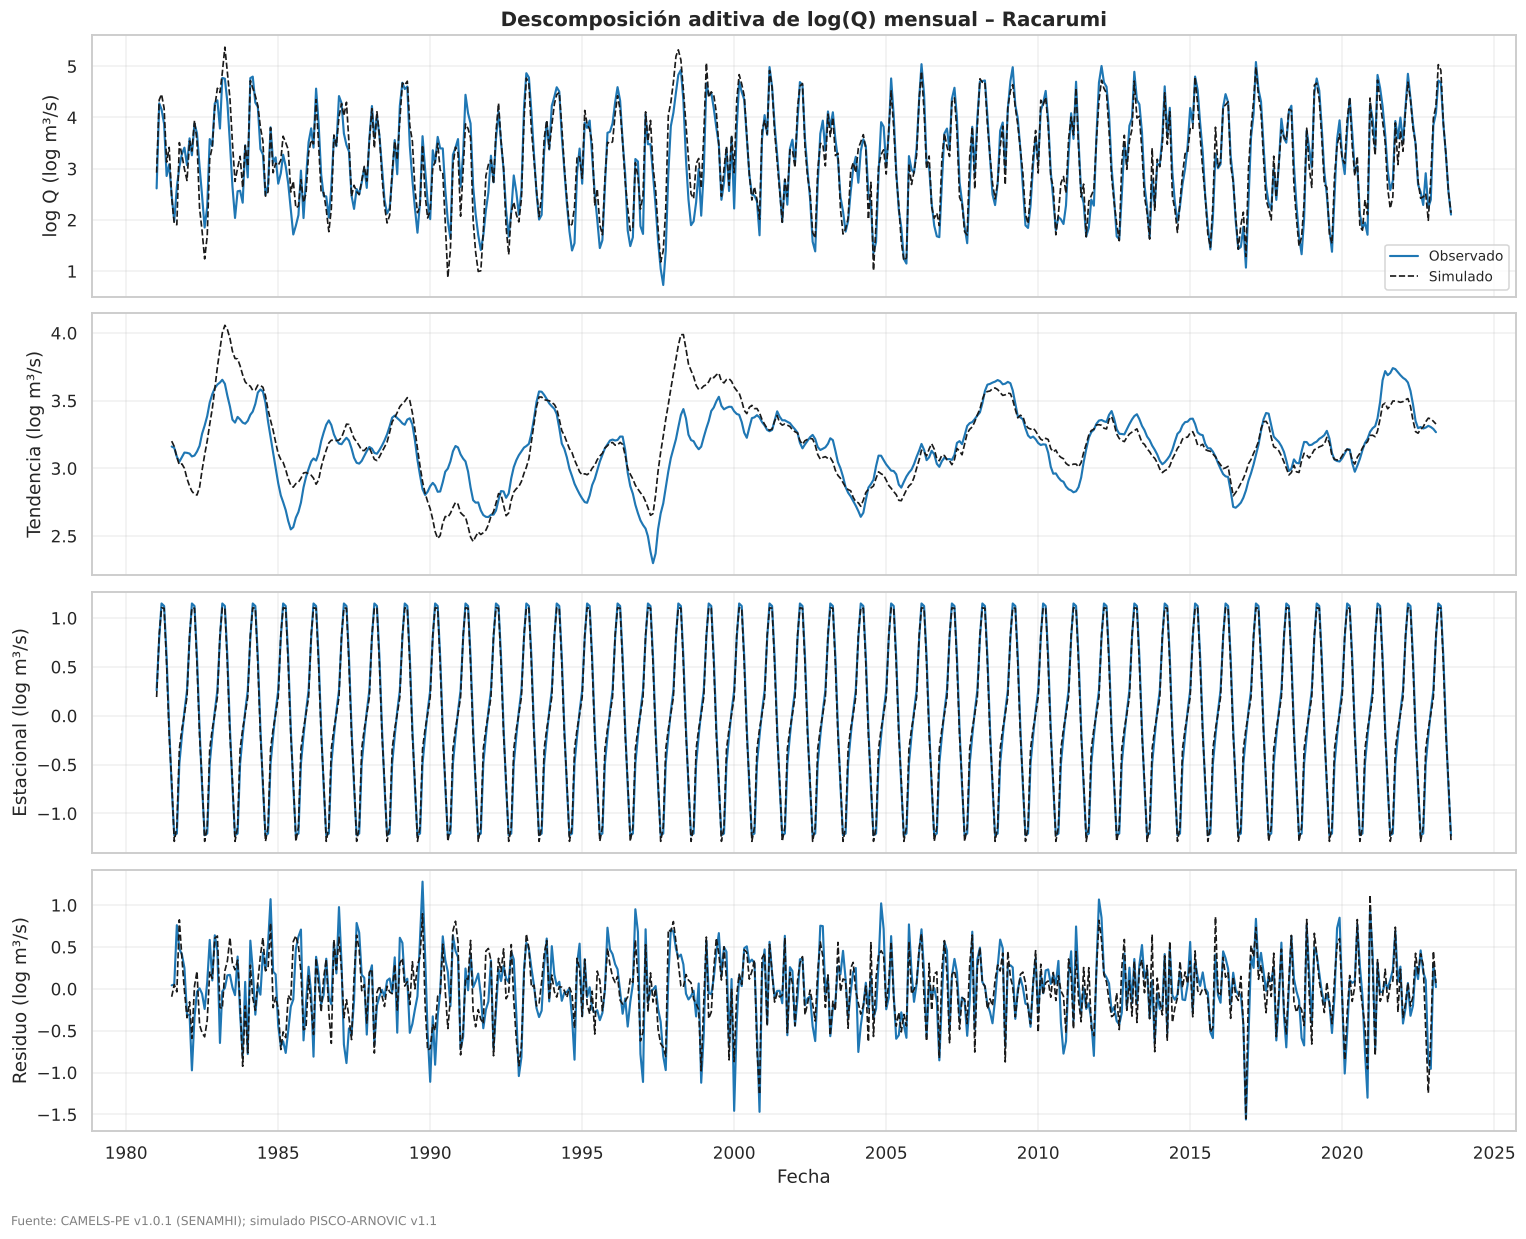

Amplitud estacional (log): obs = 2.372 (factor ×10.7); sim = 2.390 (factor ×10.9)
Pendiente de la tendencia obs (log/año): 0.0032
ADF residuo obs: p = 0.0000


In [38]:
qm = serie_mensual_valida(series['Racarumi']['qobs_dep']).asfreq('MS')
qm_int = qm.interpolate(limit=1, limit_area='inside')
v2 = qm_int.notna()
g2 = (v2 != v2.shift()).cumsum()
largo = v2.groupby(g2).transform('sum').where(v2)
tramo = qm_int[g2 == g2[largo == largo.max()].iloc[0]]
print(f"Tramo continuo usado: {tramo.index.min():%Y-%m} a {tramo.index.max():%Y-%m} ({len(tramo)} meses; "
      f"meses interpolados: {int(qm.loc[tramo.index].isna().sum())}); mínimo mensual = {tramo.min():.2f} m³/s")
sim_tramo = series['Racarumi']['qsim'].resample('MS').mean().loc[tramo.index]
desc_o = seasonal_decompose(np.log(tramo), model='additive', period=12)
desc_s = seasonal_decompose(np.log(sim_tramo), model='additive', period=12)
fig, ejes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
for ax, comp, et_ in zip(ejes, ['observed', 'trend', 'seasonal', 'resid'], ['log Q', 'Tendencia', 'Estacional', 'Residuo']):
    ax.plot(getattr(desc_o, comp), color=COLORES['Racarumi'], lw=1.4, label='Observado')
    ax.plot(getattr(desc_s, comp), color='k', ls='--', lw=1.1, label='Simulado')
    ax.set_ylabel(et_ + ' (log m³/s)'); ax.grid(True, alpha=0.3)
ejes[0].legend(fontsize=9); ejes[-1].set_xlabel('Fecha')
ejes[0].set_title('Descomposición aditiva de log(Q) mensual – Racarumi', fontsize=13, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig13_descomposicion_Racarumi.png', dpi=200, bbox_inches='tight')
plt.show()
amp_o = desc_o.seasonal.max() - desc_o.seasonal.min()
amp_s = desc_s.seasonal.max() - desc_s.seasonal.min()
print(f"Amplitud estacional (log): obs = {amp_o:.3f} (factor ×{np.exp(amp_o):.1f}); sim = {amp_s:.3f} (factor ×{np.exp(amp_s):.1f})")
print(f"Pendiente de la tendencia obs (log/año): "
      f"{stats.linregress(np.arange(desc_o.trend.dropna().size) / 12, desc_o.trend.dropna()).slope:.4f}")
print(f"ADF residuo obs: p = {adfuller(desc_o.resid.dropna())[1]:.4f}")

**Interpretación** (Racarumi, tramo continuo 1981-01 a 2023-08; 512 meses, 2 interpolados):
- **Estacionalidad:** domina la señal, con un factor de **×10.7** entre el mes más húmedo y el más seco en el observado (×10.9 en el simulado). El ciclo anual está bien reproducido.
- **Tendencia:** sin tendencia de largo plazo (pendiente +0.003 log/año), con oscilaciones interanuales. El simulado sigue al observado, salvo en **1983 y 1997–1999**, donde su tendencia queda muy por encima (hasta ~0.4–0.6 log): **sobreestima los años de El Niño**, coherente con las razones obs/sim de 0.63–0.68 de 5.3.
- **Residuo:** estacionario (ADF p < 0.001), con anomalías de hasta ±1.5 log.

### 8.4 Mapa de la cuenca y las estaciones
(a) Contexto: las 136 cuencas de CAMELS-PE con la del Chancay-Lambayeque hasta Racarumi resaltada; (b) acercamiento: subcuencas de Racarumi y Cirato, estaciones coloreadas por KGE y con tamaño según % de vacíos, y las otras cuatro estaciones del grupo anidado como referencia; (c) mapa interactivo Folium (Ses2).

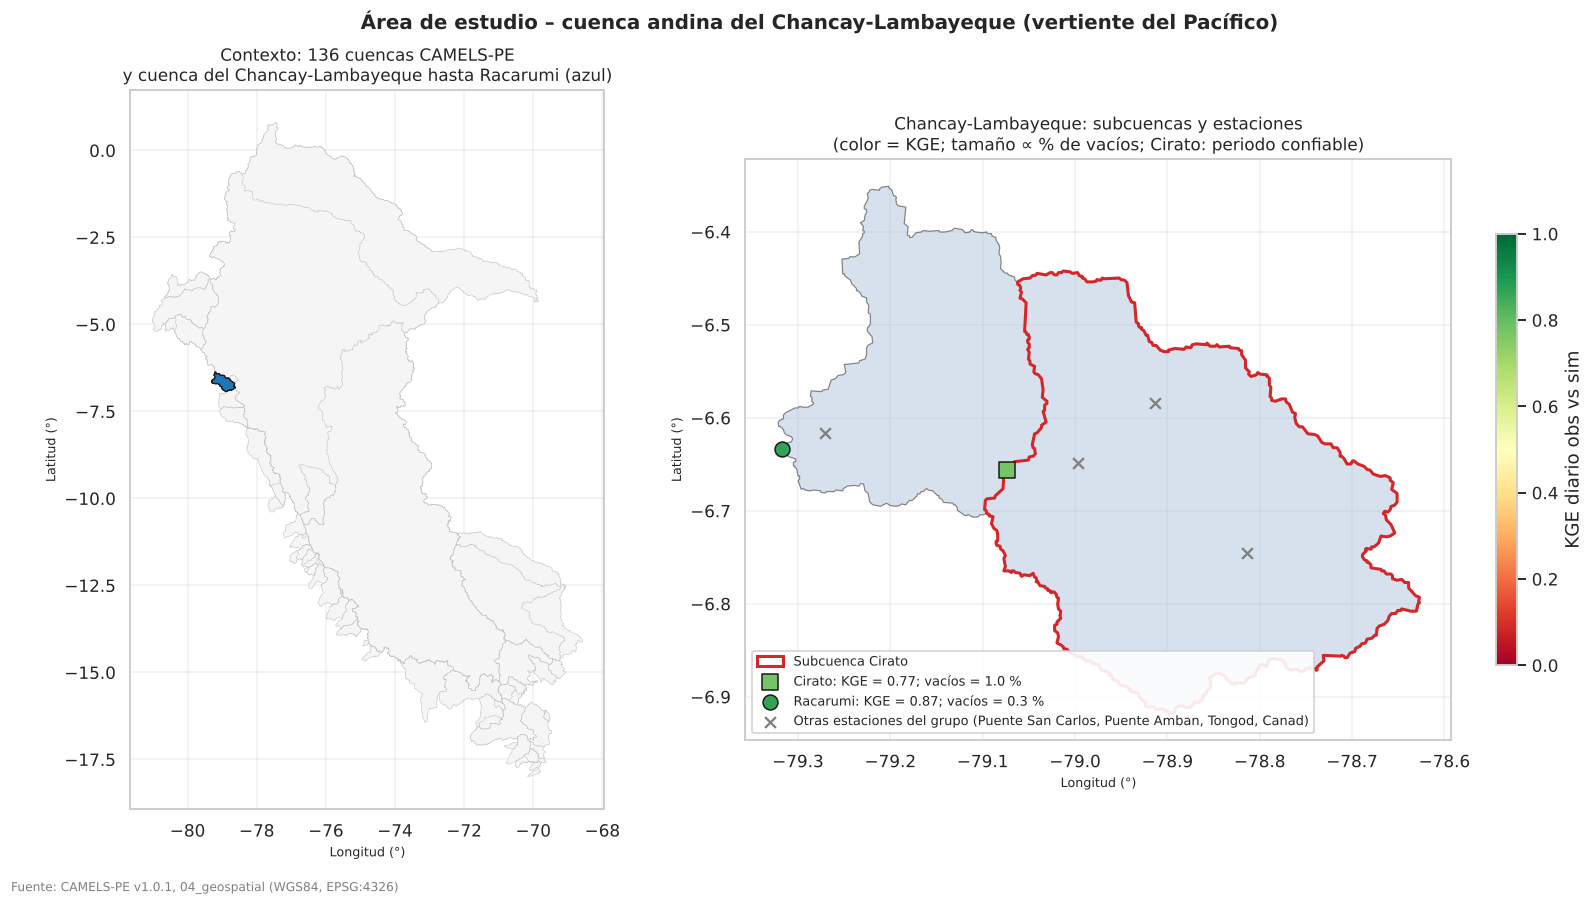

Mapa interactivo guardado en salidas/mapa_estaciones_chancay.html


In [39]:
pol = cuencas_gpkg.set_index('gauge_id')
subcuencas = pol.loc[list(ESTACIONES)].copy()
subcuencas['estacion'] = subcuencas.index.map(ESTACIONES)
pts_todos = puntos_gpkg.set_index('gauge_id')
pts = pts_todos.loc[list(ESTACIONES)].copy()
pts['estacion'] = pts.index.map(ESTACIONES)
pts['KGE'] = pts['estacion'].map(tabla_metricas['KGE'])
pts['vacios'] = pts['estacion'].map(tabla_vacios['% vacíos'])
otras_est = pts_todos.loc[['PE_47E1D6C2', 'PE_47E1E358', 'PE_47E207A4', 'PE_47E1C5B4']]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={'width_ratios': [0.8, 1.3]})
cuencas_gpkg.plot(ax=ax0, color='whitesmoke', edgecolor='silver', lw=0.3)
subcuencas.loc[['PE_200907']].plot(ax=ax0, color=COLORES['Racarumi'], edgecolor='k', lw=0.8)
ax0.set_title('Contexto: 136 cuencas CAMELS-PE\ny cuenca del Chancay-Lambayeque hasta Racarumi (azul)', fontsize=11)
ax0.set_xlabel('Longitud (°)'); ax0.set_ylabel('Latitud (°)'); ax0.grid(True, alpha=0.3)

subcuencas.loc[['PE_200907']].plot(ax=ax1, color='lightsteelblue', edgecolor='k', lw=0.8, alpha=0.5)
subcuencas.loc[['PE_4724D566']].plot(ax=ax1, facecolor='none', edgecolor=COLORES['Cirato'], lw=2, label='Subcuenca Cirato')
norma = plt.Normalize(0, 1)
for marcador, (gid, r) in zip(['s', 'o'], pts.iterrows()):
    ax1.scatter(r.geometry.x, r.geometry.y, c=[plt.cm.RdYlGn(norma(r['KGE']))], s=90 + 15 * r['vacios'], marker=marcador,
                edgecolors='k', zorder=5, label=f"{r['estacion']}: KGE = {r['KGE']:.2f}; vacíos = {r['vacios']:.1f} %")
ax1.scatter(otras_est.geometry.x, otras_est.geometry.y, marker='x', color='gray', s=50, zorder=4,
            label='Otras estaciones del grupo (Puente San Carlos, Puente Amban, Tongod, Canad)')
plt.colorbar(plt.cm.ScalarMappable(cmap='RdYlGn', norm=norma), ax=ax1, shrink=0.6, label='KGE diario obs vs sim')
ax1.legend(loc='lower left', fontsize=8.5, framealpha=0.9)
ax1.set_title('Chancay-Lambayeque: subcuencas y estaciones\n(color = KGE; tamaño ∝ % de vacíos; Cirato: periodo confiable)', fontsize=11)
ax1.set_xlabel('Longitud (°)'); ax1.set_ylabel('Latitud (°)'); ax1.grid(True, alpha=0.3)
fig.suptitle('Área de estudio – cuenca andina del Chancay-Lambayeque (vertiente del Pacífico)', fontsize=13, fontweight='bold')
nota_fuente(fig, 'Fuente: CAMELS-PE v1.0.1, 04_geospatial (WGS84, EPSG:4326)')
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig14_mapa_estaciones.png', dpi=200, bbox_inches='tight')
plt.show()

centro = subcuencas.loc[['PE_200907']].to_crs(epsg=32717).centroid.to_crs(epsg=4326).iloc[0]
mapa = folium.Map(location=[centro.y, centro.x], zoom_start=9, tiles='OpenStreetMap')
for gid, fila in subcuencas.iterrows():
    folium.GeoJson(subcuencas.loc[[gid]].__geo_interface__, name=fila['estacion'],
                   style_function=lambda f, c=COLORES[fila['estacion']]: {'color': c, 'weight': 2, 'fillOpacity': 0.1}).add_to(mapa)
for gid, fila in pts.iterrows():
    folium.CircleMarker(location=[fila.geometry.y, fila.geometry.x], radius=9, color='white', weight=2, fill=True,
                        fill_color=COLORES[fila['estacion']], fill_opacity=0.9,
                        popup=folium.Popup(f"<b>{fila['estacion']}</b> ({gid})<br>Área: {area[fila['estacion']]:.0f} km²<br>"
                                           f"KGE: {fila['KGE']:.2f}<br>Vacíos: {fila['vacios']:.1f} %", max_width=220),
                        tooltip=fila['estacion']).add_to(mapa)
folium.LayerControl().add_to(mapa)
mapa.save(str(RUTA_SALIDAS / 'mapa_estaciones_chancay.html'))
print('Mapa interactivo guardado en', RUTA_SALIDAS / 'mapa_estaciones_chancay.html')
mapa

**Interpretación:** el mapa ubica la cuenca del Chancay-Lambayeque en la vertiente del Pacífico (norte del Perú).
- **Cirato** (cuadrado) drena la mitad oriental y alta de la cuenca.
- **Racarumi** (círculo) está en el extremo occidental, a la salida hacia el valle.
- Puente San Carlos, Puente Amban, Tongod y Canad aparecen como referencia.

**Color y tamaño:** los dos colores verdes indican que el simulado es razonable en ambas (KGE 0.77 y 0.87). Ambas tienen pocos vacíos (1.0 % y 0.3 %). El mapa interactivo se guarda en `salidas/mapa_estaciones_chancay.html`.

---
## 9. Síntesis del diagnóstico

### 9.1 Calidad de datos por estación
Cada estación se clasifica con criterios fijados de antemano (guía del equipo, 1.6): **apta** = ≥ 15 años y < 10 % de vacíos sin inconsistencias; **apta con reservas** = cumple uno de los dos o tiene inconsistencias documentadas; **no apta** = no cumple ninguno y < 1 año pareado. Los años se cuentan en el periodo utilizable (en Cirato, fechas confiables) y se añade si el **registro completo** es utilizable.

In [40]:
filas = []
for nombre in ESTACIONES.values():
    anios = pareados[nombre].shape[0] / 365.25
    vac = tabla_vacios.loc[nombre, '% vacíos']
    crit_largo, crit_vacios = anios >= 15, vac < 10
    inconsist = nombre == 'Cirato'
    if crit_largo and crit_vacios and not inconsist:
        clase = 'apta'
    elif (crit_largo or crit_vacios) and anios >= 1:
        clase = 'apta con reservas'
    else:
        clase = 'no apta'
    filas.append({'estación': nombre, 'periodo utilizable': f"{pareados[nombre].index.min():%Y-%m} a {pareados[nombre].index.max():%Y-%m}",
                  'años con dato válido': round(anios, 1), '% vacíos': vac, '≥ 15 años': crit_largo, '< 10 % vacíos': crit_vacios,
                  'inconsistencias documentadas': inconsist, 'registro completo utilizable': not inconsist,
                  'errores eliminados': int(banderas[nombre].sum()), 'KGE': round(tabla_metricas.loc[nombre, 'KGE'], 3),
                  'clasificación': clase})
tabla_calidad = pd.DataFrame(filas).set_index('estación')
tabla_calidad.to_csv(RUTA_TAB / 'tabla_calidad_estaciones.csv')
tabla_calidad

,periodo utilizable,años con dato válido,% vacíos,≥ 15 años,< 10 % vacíos,inconsistencias documentadas,registro completo utilizable,errores eliminados,KGE,clasificación
estación,,,,,,,,,,
Cirato,2022-08 a 2025-12,3.4,1.04,False,True,True,False,0,0.773,apta con reservas
Racarumi,1981-01 a 2023-08,42.5,0.32,True,True,False,True,15,0.867,apta


**Interpretación:**
- **Racarumi es "apta":**
  - 42.5 años de dato válido y solo 0.32 % de vacíos;
  - homogénea (5.3), con 15 errores puntuales eliminados.

  Su única limitación es que CAMELS-PE termina en 2023-08-31.
- **Cirato es "apta con reservas":** la clasificación se refiere **solo a 2022-08 – 2025-12** (3.4 años, 1.04 % de vacíos). Su registro completo (2008–2022) **no es utilizable** por el error de fechas.

### 9.2 Hallazgos clave

| # | Hallazgo | Evidencia (sección) |
|---|---|---|
| 1 | **Racarumi es una serie de alta calidad:** 42.5 años, 0.32 % de vacíos y homogénea. Bien fechada: desfase obs–sim estable de −1 día en todos los años. | 2.7, 3.1, 5.3 |
| 2 | **Cirato tiene un error de fechas en 2009–2022:** su desfase crece ~1 día por año hasta 12 días. Fechas confiables solo desde **2022-08-01**. La lluvia lo confirma: respuesta a 12 días frente a 2 en el periodo confiable. | 2.7, 6.2 |
| 3 | El periodo común confiable de ambas estaciones en CAMELS-PE es de solo **13 meses**, porque Racarumi termina el 2023-08-31. | 2.7, 2.8 |
| 4 | **Racarumi lleva apenas 7 % más agua que Cirato**, aunque drena 47 % más área (mediana 1.07): hay captaciones o pérdidas entre ambas. | 2.8 |
| 5 | **Simulado:** bueno en Racarumi (NSE 0.73, BE 0.52) y aceptable en Cirato (NSE 0.73, BE 0.45), pero sobreestima Cirato en 17 % y es 28–42 % más suave que el río. Hay huella de mapeo de cuantiles (máximos idénticos en otra fecha). | 2.6, 5.1, H4 |
| 6 | Racarumi tenía 5 caudales en 0 (3 de ellos en plena época de lluvias, 2022-12 a 2023-02) y otros 10 errores puntuales, todos eliminados con evidencia. | 4.3 |
| 7 | La lluvia anticipa el caudal en ~2 días; Cirato **no anticipa** a Racarumi a escala diaria. | 6.2, 6.3 |

**Respuesta a la pregunta del diagnóstico:**
- **Racarumi:** es apta y es la serie de referencia de la cuenca.
- **Cirato:** solo es utilizable desde agosto de 2022.
- **Simulado:** **no debe sustituir al observado** (decisión 7.5).

### 9.3 Limitaciones
- **Error de Cirato y mapeo de cuantiles:** son inferencias a partir de los datos; no están documentados en lo revisado.
- **Periodos cortos:** el periodo común confiable (13 meses) y el periodo confiable de Cirato (3.4 años) limitan las pruebas entre estaciones y en Cirato.
- **Pérdidas entre estaciones:** no pueden atribuirse a una causa, porque CAMELS-PE no registra la operación de captaciones ni presas. Tampoco se pudo explicar la caída de Racarumi a mediados de marzo de 2023.
- **Otras variables:** no hay ETP después de 2016 ni temperatura después de 2020.

### 9.4 Recomendaciones para el modelamiento
1. **Usar Racarumi como estación objetivo de la cuenca**, con un periodo reciente (2016–2023) reservado para evaluar.
2. **Consultar a SENAMHI por el desfase de fechas de Cirato (2009–2022).** Si se confirma un desfase año a año, una realineación podría recuperar ese periodo, pero no debe hacerse sin confirmación.
3. **No usar Cirato como "estación aguas arriba" para anticipar a Racarumi a escala diaria** (6.3). La anticipación debe venir de la lluvia (rezagos de 1–7 días).
4. **Para alertas, considerar las captaciones entre Cirato y Racarumi:** el caudal de Racarumi no es solo respuesta natural a la lluvia (2.8). Conviene consultar al operador de la estación por la operación de la infraestructura.
5. **Indicadores para la selección de cuencas del proyecto:** años útiles, % de vacíos, integridad temporal (2.7), homogeneidad (5.3), BE (5.1) y RB/tiempo de decorrelación (7.4).

**Cómo se aplicaron en el modelamiento (cuadernos 01–09):** Racarumi es la estación objetivo de la cuenca; la división temporal final es entrenamiento hasta 2008, validación 2009–2015 (con un bloque de selección 2012–2015) y prueba 2016–2023; Cirato se evalúa solo de forma exploratoria (cuadernos 05 y 07), porque sus fechas confiables cubren apenas 13 meses en común con Racarumi; y la lluvia de la cuenca se evalúa como entrada en el cuaderno 06.

### 9.5 Lista de verificación de calidad

| Verificación | Estado | Evidencia |
|---|---|---|
| Ejecución completa (*Restart & Run All*) con rutas relativas | ✅ | Todas las celdas de código ejecutadas en orden, 0 errores, 0 advertencias en stderr |
| Vacíos sin documentar | ✅ | Vacíos por estación y variable (3.1). El periodo excluido de Cirato se declara como error de fechas, no como vacío (2.7, 3.3) |
| Outliers eliminados con evidencia | ✅ | 15 puntos con motivo (`tabla_outliers_eliminados.csv`); ninguna crecida con lluvia eliminada |
| Hipótesis del diagnóstico evaluadas | ✅ | H1–H4 con prueba, supuestos, estadístico, p o IC, tamaño de efecto y conclusión (7.1–7.4); decisión en 7.5 |
| Hipótesis del proyecto | ✅ en el modelamiento | HP1–HP3 requieren modelos: se contrastan con las dos cuencas seleccionadas en los cuadernos 01–04 (resumen en el `README.md` principal) |
| Figuras con título, unidades, leyenda y fuente, e interpretadas | ✅ | 14 figuras (`salidas/figuras/`), cada una seguida de su interpretación |
| Cifras de las interpretaciones = salidas | ✅ | Revisadas contra las salidas y figuras de esta ejecución |
| Pendientes abiertos | ⚠️ | Confirmar con SENAMHI el error de Cirato y el mapeo de cuantiles |

---
## 10. Referencias

**Datos y documentación**
- Llauca, H., Montesinos-Caceres, C., Gutierrez-Reynaga, M. y Lavado-Casimiro, W. (2026). CAMELS-PE: Hydrometeorological time series and catchment attributes for 136 catchments in Peru. *Earth System Science Data Discussions*. https://doi.org/10.5194/essd-2026-386
- SENAMHI (2026). *CAMELS-PE: Technical documentation, version 1.0.1* y `README.md` del dataset.
- Llauca, H., Leon, K. y Lavado, W. (2023). Construction of a daily streamflow dataset for Peru using a similarity-based regionalization approach and a hybrid modeling framework. *Journal of Hydrology: Regional Studies*, 47, 101381. https://doi.org/10.1016/j.ejrh.2023.101381 — ficha HydroShare *The PISCO-ARNOVIC Daily Streamflow Product for Peru (v1.1)*: https://www.hydroshare.org/resource/f723d6c762ca45b6936dd9489bc44842

**Métodos**
- Baker, D. B., Richards, R. P., Loftus, T. T. y Kramer, J. W. (2004). A new flashiness index: characteristics and applications to midwestern rivers and streams. *JAWRA*, 40(2), 503–522.
- Clark, M. P. et al. (2021). The abuse of popular performance metrics in hydrologic modeling. *Water Resources Research*, 57, e2020WR029001.
- Gupta, H. V., Kling, H., Yilmaz, K. K. y Martinez, G. F. (2009). Decomposition of the mean squared error and NSE performance criteria. *Journal of Hydrology*, 377, 80–91.
- Iglewicz, B. y Hoaglin, D. C. (1993). *How to Detect and Handle Outliers*. ASQC Quality Press.
- Knoben, W. J. M., Freer, J. E. y Woods, R. A. (2019). Technical note: Inherent benchmark or not? Comparing Nash–Sutcliffe and Kling–Gupta efficiency scores. *HESS*, 23, 4323–4331. https://doi.org/10.5194/hess-23-4323-2019
- Lang, M., Ouarda, T. B. M. J. y Bobée, B. (1999). Towards operational guidelines for over-threshold modeling. *Journal of Hydrology*, 225, 103–117.
- Moriasi, D. N. et al. (2007). Model evaluation guidelines for systematic quantification of accuracy in watershed simulations. *Transactions of the ASABE*, 50(3), 885–900.
- Nash, J. E. y Sutcliffe, J. V. (1970). River flow forecasting through conceptual models part I. *Journal of Hydrology*, 10(3), 282–290.
- Pushpalatha, R., Perrin, C., Le Moine, N. y Andréassian, V. (2012). A review of efficiency criteria suitable for evaluating low-flow simulations. *Journal of Hydrology*, 420–421, 171–182.
- Schaefli, B. y Gupta, H. V. (2007). Do Nash values have value? *Hydrological Processes*, 21, 2075–2080.
- WMO (2017). *WMO Guidelines on the Calculation of Climate Normals* (WMO-No. 1203), §4.4.1.
- Yilmaz, K. K., Gupta, H. V. y Wagener, T. (2008). A process-based diagnostic approach to model evaluation. *Water Resources Research*, 44, W09417.